# Task 4 – Datengrundlage

**Ziel:** Beschreibung aller Eingangsdaten für Task 4: BDEW-Standardlastprofile (Haushalt, Gewerbe, Landwirtschaft, Haushalt mit PV, Haushalt mit PV und Speicher), Windenergieanlage, PV-Modul, Wetterdaten und die Erzeugungsanlagen der Szenarien (Windpark, PV-Freiflächenanlage) sowie das CIGRE-Mittelspannungsnetz.

**Aufbau des Notebooks:**

1. Daten laden: Lastprofile, Windenergieanlage, PV-Anlage, Wetterdaten, Erzeugungsanlagen für Task 4
2. Netzaufbau CIGRE-MV: Netzplan und Komponenten

## Importe

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

# Alle Module liegen im Ordner dieses Notebooks (task4)
TASK4 = Path(".")
import profiles as pr
import weather as wt
from profiles import Lastprofil, Month, DayType, Season

import plots as plots

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 20 unterscheidbare Farben, damit alle 15 Busse in einem Diagramm unterscheidbar bleiben
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

Module im Ordner `task4` (Beschreibung siehe `README.md`):

- `profiles.py`: Einlesen und Aufbereiten der BDEW-Standardlastprofile 2025 (Wochen bilden, Dynamisierung, Skalierung), übernommen aus Task 2 und erweitert
- `weather.py`: Wetterdaten (Open-Meteo) und Umrechnung in PV- und Windleistung über die Kennlinien, übernommen aus Task 2
- `plots.py`: Diagramme mit einheitlicher Zeitachse (Uhrzeit im 6-Stunden-Takt, Tageswechsel als senkrechte Linie, Datum über jedem Tag) Komponentenübersicht des Netzes und `table()` für formatierte Tabellen (farbig, wenn `jinja2` installiert ist)
- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für die saisonale Lastflussrechnung (Abschnitt 3.2)

In [2]:
def monatstabelle(s, groesse, stat="max", elemente=None):
    """Monatstabelle (Elemente × Monate) einer Simulation, farbig hinterlegt.
    groesse: "Spannung", "Winkel", "Leitung" oder "Trafo"; stat: "max", "min" oder "mean"."""
    art = {  # Ergebnistabelle, Titel, Zahlenformat, Farbskala, Bereich der Farbskala
        "Spannung": ("vm_pu", "U {} [pu]", "{:.3f}",
                     "RdYlGn_r" if stat == "max" else "RdYlGn", (1.0, 1.08) if stat == "max" else (0.92, 1.03)),
        "Winkel":   ("va_degree", "Winkel {} [°]", "{:.2f}", "coolwarm", (None, None)),
        "Leitung":  ("line_loading", "Leitung {} [%]", "{:.1f}", "YlOrRd", (0, 100)),
        "Trafo":    ("trafo_loading", "Trafo {} [%]", "{:.1f}", "YlOrRd", (0, 100)),
    }
    attr, titel, fmt, cmap, (vmin, vmax) = art[groesse]
    df = getattr(s.results, attr)
    if elemente is not None:
        df = df[elemente]
    monat = s.results.info["month"].map(lambda m: Month[m].label)
    t = df.groupby(monat).agg(stat).T[[m.label for m in Month]]
    t.index.name = titel.format(stat)
    return t.style.format(fmt, na_rep="–").background_gradient(cmap=cmap, vmin=vmin, vmax=vmax, axis=None)

## 1 Daten laden

Alle Eingangsdaten werden einmal zu Beginn geladen und stehen danach in Variablen zur Verfügung:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `data/BDEW_H25_Haushalte.csv`, `data/BDEW_G25_Gewerbe.csv`, `data/BDEW_L25_Landwirtschaft.csv`, `data/BDEW_P25_PV.csv`, `data/BDEW_S25_PV_Speicher.csv` | BDEW-Standardlastprofile 2025: H25 (Haushalt), G25 (Gewerbe), L25 (Landwirtschaft), P25 (Haushalt mit PV), S25 (Haushalt mit PV und Speicher), je 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `data/weather_weeks_2025.csv` | je Monat eine typische Woche (stündlich) mit Wetter und berechneter PV- und Windleistung |

Die Wetterdaten wurden in Task 2 einmalig über die Open-Meteo-API abgerufen und als CSV gespeichert; das Notebook benötigt deshalb keinen Internetzugang.

In [3]:
DATA = TASK4 / "data"
WEATHER_FILE = DATA / "weather_weeks_2025.csv"

PROFILES = pr.load_profiles(DATA)
WEATHER = wt.load_weather_weeks(WEATHER_FILE)                  # {Month: DataFrame mit 168 Stunden}
WEEK_STARTS = {m: df.index[0] for m, df in WEATHER.items()}     # Montag jeder Wetterwoche

ANNUAL_KWH = 3500                                               # Jahresverbrauch eines Haushalts [kWh/a]

for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
G25 – Gewerbe allgemein: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
L25 – Landwirtschaft: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
P25 – Haushalt mit PV (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
S25 – Haushalt mit PV und Speicher (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
Wetter:     12 Wochen × 168 Stunden


### 1.1 Lastprofile (BDEW H25, G25, L25, P25, S25)

#### Haushalte (H25)

**Herkunft:** Das Standardlastprofil H25 ist der Nachfolger des Haushaltsprofils H0 aus dem Jahr 1999. Es wurde im Auftrag des BDEW von der BTU EVU Beratung GmbH aus Abrechnungsdaten von 62 Verteilnetzbetreibern der Jahre 2018 und 2019 erstellt [1, S. 3]. Weil zu dieser Zeit bereits PV-Anlagen in Betrieb waren, enthält das Profil einen moderaten PV-Eigenverbrauch [1, S. 3]. Die Daten stammen aus der BDEW-Veröffentlichung der repräsentativen Profile 2025 [2].

**Aufbau der Datei:** 12 Monate × 3 Tagtypen (WT = Werktag, SA = Samstag, FT = Sonn- und Feiertag) mit je 96 Viertelstundenwerten. Die Werte sind Energiemengen in kWh je Viertelstunde, normiert auf einen Jahresverbrauch von 1 Mio. kWh [1, S. 3].

**Aufbereitung:**

1. *Woche bilden:* Montag bis Freitag erhalten den Tagtyp WT, Samstag SA, Sonntag FT. Wochen mit gesetzlichem Feiertag (NRW) werden bei der Auswahl der Wochen ausgeschlossen, damit die Annahme „fünf Werktage“ gilt.
2. *Leistung:* Die Energie einer Viertelstunde wird in die mittlere Leistung umgerechnet: P = E / 0,25 h = 4 · E.
3. *Dynamisierung:* H25 ist „entdynamisiert“; beim Ausrollen ist die Dynamisierungsfunktion anzuwenden [1, S. 3–4]. Sie bildet den Jahresgang des Verbrauchs ab (im Winter höher, im Sommer niedriger):

   F(t) = −3,92·10⁻¹⁰·t⁴ + 3,2·10⁻⁷·t³ − 7,02·10⁻⁵·t² + 2,1·10⁻³·t + 1,24 &nbsp;&nbsp; (t = Tag des Jahres) [3]

   Der Faktor wird auf vier Nachkommastellen gerundet [1, S. 4] und liegt zwischen etwa 0,79 (Juli/August) und 1,26 (Ende Dezember).
4. *Skalierung:* P_Haushalt = P_norm · F(t) · W_a / 1 000 000 kWh mit dem Jahresverbrauch W_a des Haushalts.
5. *Stundenwerte:* Mittelwert der vier Viertelstundenleistungen einer Stunde.

**Vorzeichen und Einheiten:** Die Last wird im Verbraucherzählpfeilsystem angegeben (Bezug positiv), in pandapower in MW (`unit="MW"`). Die Blindleistung ist im Profil nicht enthalten und wird bei der Einbindung ins Netz über einen Leistungsfaktor festgelegt.

#### Gewerbe (G25)

**Herkunft:** G25 („Gewerbe allgemein“) ist das Standardlastprofil für Gewerbekunden aus derselben BDEW-Veröffentlichung 2025 wie H25 [2]. Es ersetzt das frühere Profil G0 und beschreibt einen durchschnittlichen Gewerbebetrieb ohne ausgeprägte Branchencharakteristik.

**Aufbau:** wie H25 – 12 Monate × 3 Tagtypen (WT, SA, FT) mit je 96 Viertelstundenwerten in kWh, normiert auf 1 Mio. kWh Jahresverbrauch.

**Unterschied zu H25:** Für G25 ist die Dynamisierungsfunktion **nicht** anzuwenden (Hinweis im Dateikopf und [1]). Die Aufbereitung beschränkt sich daher auf Wochenbildung, Umrechnung in Leistung (P = 4 · E), Skalierung auf den Jahresverbrauch und Mittelung auf Stundenwerte.

**Verwendung:** Im CIGRE-Netz gibt es Wohngebietslasten (R, *residential*) und Gewerbe-/Industrielasten (CI, *commercial/industrial*). Für die zeitliche Variation der R-Lasten wird H25, für die CI-Lasten G25 verwendet.

#### Landwirtschaft (L25)

**Herkunft:** L25 ist das Standardlastprofil für landwirtschaftliche Betriebe aus der BDEW-Veröffentlichung 2025 [1], [2]. Weil keine spezifischen Messzeitreihen vorlagen, beruht es auf dem bisherigen VDEW-Profil L0 und wurde auf die neue Form mit 12 Monaten gebracht. Es wird ein einziges Profil für alle Landwirtschaftsbetriebe bereitgestellt [1, S. 4].

**Aufbau und Aufbereitung:** wie G25 – 12 Monate × 3 Tagtypen mit je 96 Viertelstundenwerten, normiert auf 1 Mio. kWh Jahresverbrauch [1, S. 3]. L25 enthält **keine** Dynamisierung [1, S. 4]; die Aufbereitung entspricht daher G25.

**Hinweis zur Datei:** Die CSV-Datei enthält am Zeilenende leere Spalten; beim Einlesen werden nur die Spalten der zwölf Monate und drei Tagtypen übernommen.

**Verwendung:** In den CIGRE-Netzen gibt es keine Landwirtschaftslasten. Das Profil steht in der Simulationssoftware als `Profile.LANDWIRTSCHAFT` zur Verfügung, wird in Task 4 aber nicht verwendet.

#### Haushalt mit PV (P25)

**Herkunft:** P25 ist ein Kombinationsprofil, das den Einfluss einer PV-Anlage auf eine Haushaltslieferstelle abbildet. Ist bekannt, dass an der Lieferstelle eine PV-Anlage vorhanden ist, wird statt H25 das Profil P25 zugeordnet [1, S. 4]. Grundlage sind Messdaten aus den Jahren 2022 und 2023 von 400 intelligenten Messsystemen [1, S. 4].

**Bedeutung:** P25 beschreibt den **Strombezug** des Haushalts aus dem Netz, also den Verbrauch abzüglich des selbst genutzten PV-Stroms. Die Einspeisung der PV-Anlage ist nicht enthalten; sie wird bei den BDEW-Profilen über eigene Erzeugungsprofile abgebildet, wobei die Eigenversorgung der Haushalte zu berücksichtigen ist [1, S. 5]. P25 wird deshalb nie negativ.

**Aufbereitung:** wie H25 – das Profil ist entdynamisiert, beim Ausrollen ist die Dynamisierungsfunktion anzuwenden [1, S. 4]. Normiert auf 1 Mio. kWh Jahresbezug [1, S. 3].

**Einschränkung:** P25 bildet nur eine durchschnittliche solare Einstrahlung ab; der BDEW erwartet, dass die Güte des Profils mit weiterem PV-Ausbau abnimmt [1, S. 5]. Der Strombezug hängt in der Simulation deshalb nicht vom Wetter der jeweiligen Woche ab.

#### Haushalt mit PV und Speicher (S25)

**Herkunft:** S25 ist ein Kombinationsprofil, das zusätzlich den Einfluss eines PV-Speichers auf den Strombezug berücksichtigt. Sind an der Lieferstelle eine PV-Anlage und ein Speicher bekannt, wird statt H25 das Profil S25 zugeordnet [1, S. 5]. Grundlage sind Messdaten aus den Jahren 2022 und 2023 von 200 intelligenten Messsystemen [1, S. 5].

**Bedeutung und Aufbereitung:** wie P25 – Strombezug aus dem Netz ohne Einspeisung, entdynamisiert (Dynamisierungsfunktion anzuwenden), normiert auf 1 Mio. kWh Jahresbezug [1, S. 3, 5]. Es gilt dieselbe Einschränkung zur durchschnittlichen Einstrahlung.

**Darstellung:** Für jeden Monat werden die Profile für eine Woche in Stundenwerten gezeigt, alle bezogen auf denselben Jahresverbrauch von 1 Mio. kWh (H25, P25 und S25 dynamisiert, G25 und L25 ohne Dynamisierung). Die Woche liegt auf denselben Kalendertagen wie die typische Wetterwoche des Monats (Abschnitt 1.4), sodass Last und Erzeugung später direkt kombiniert werden können.

- erste Diagrammreihe: Haushalt (H25), Gewerbe (G25) und Landwirtschaft (L25)
- zweite Diagrammreihe: Haushalt ohne PV (H25), mit PV (P25) und mit PV und Speicher (S25)

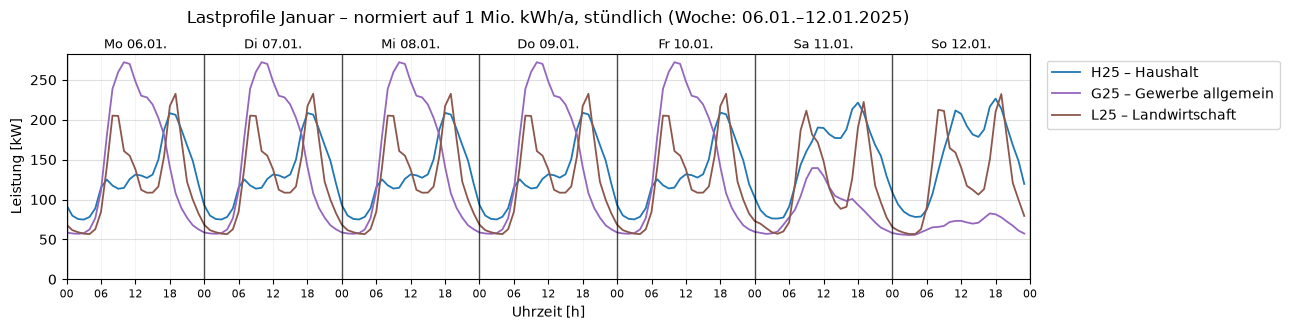

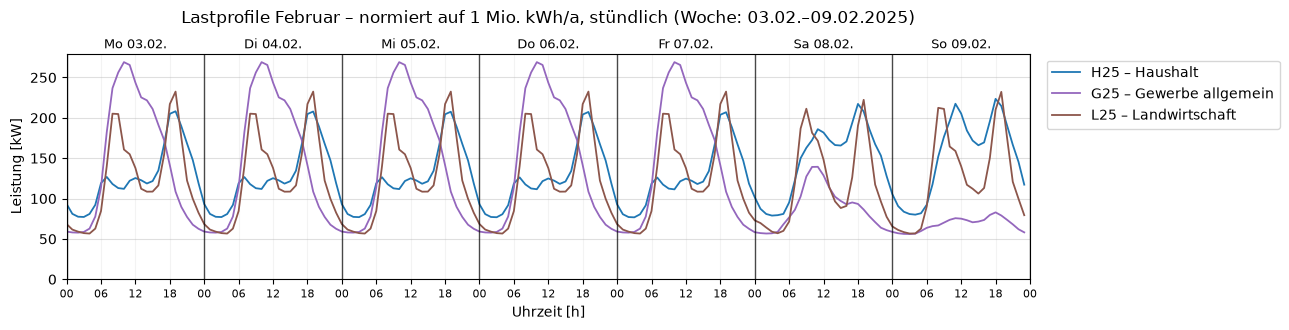

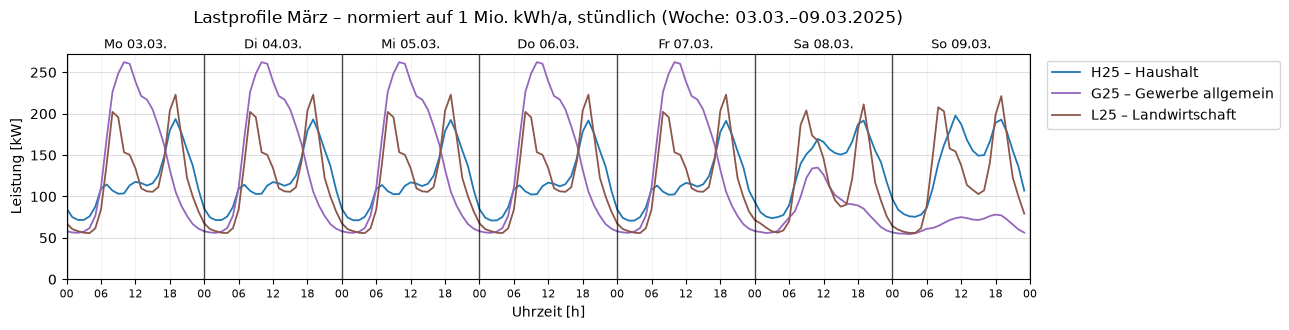

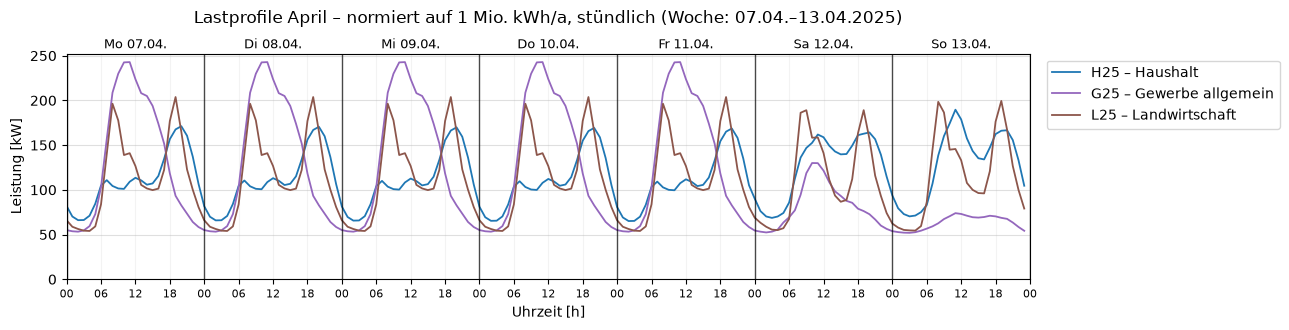

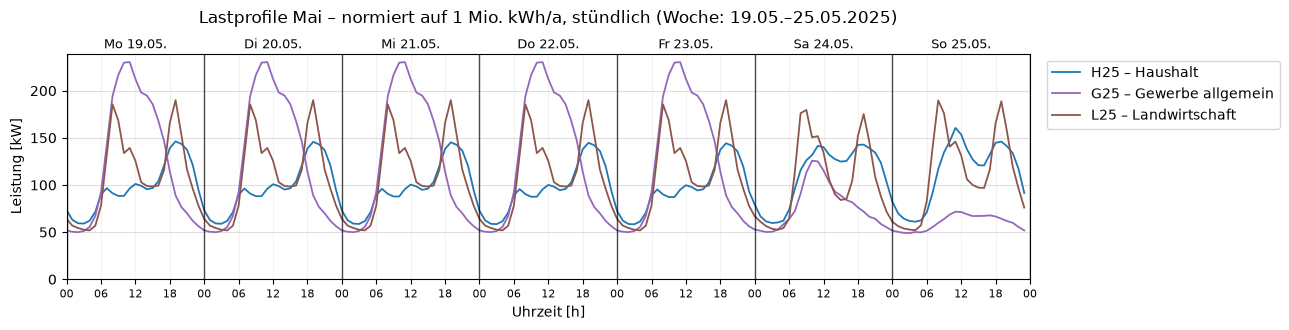

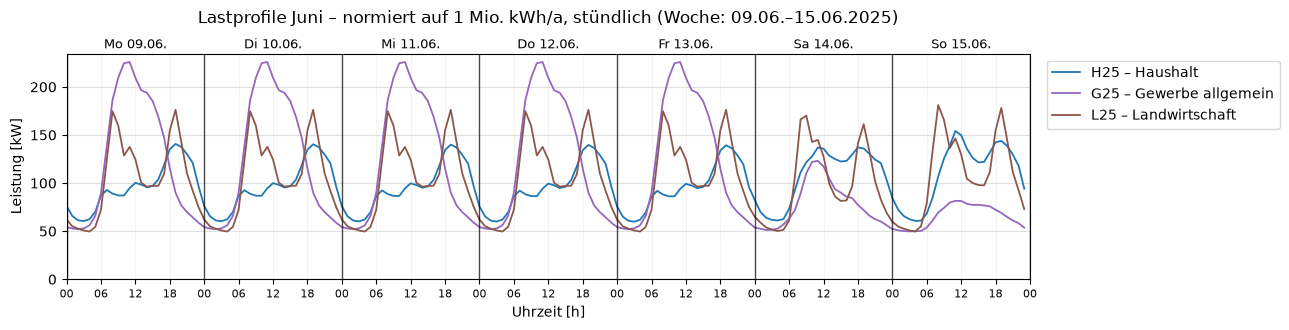

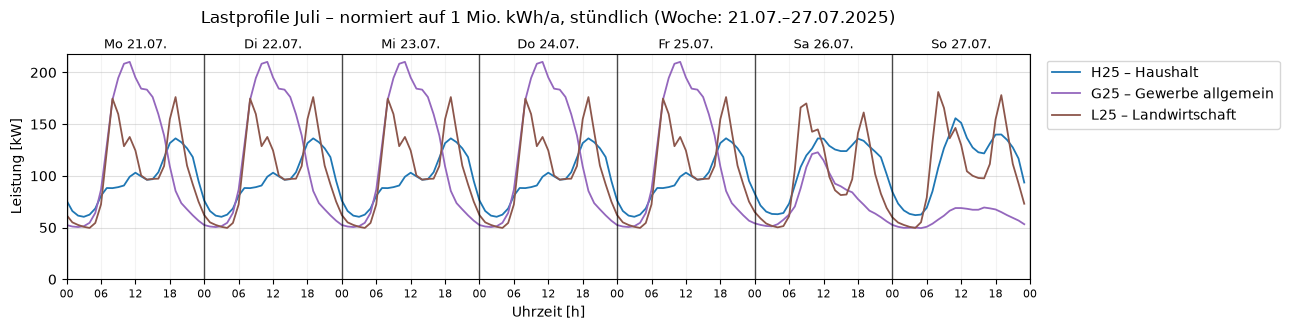

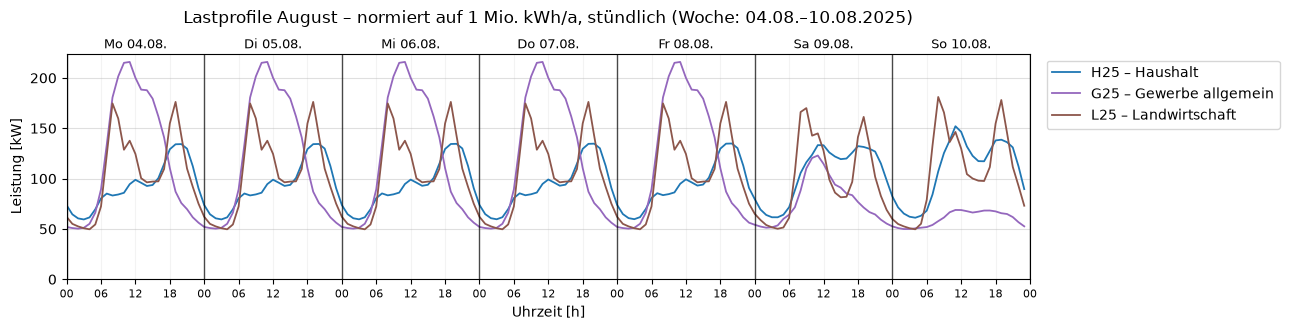

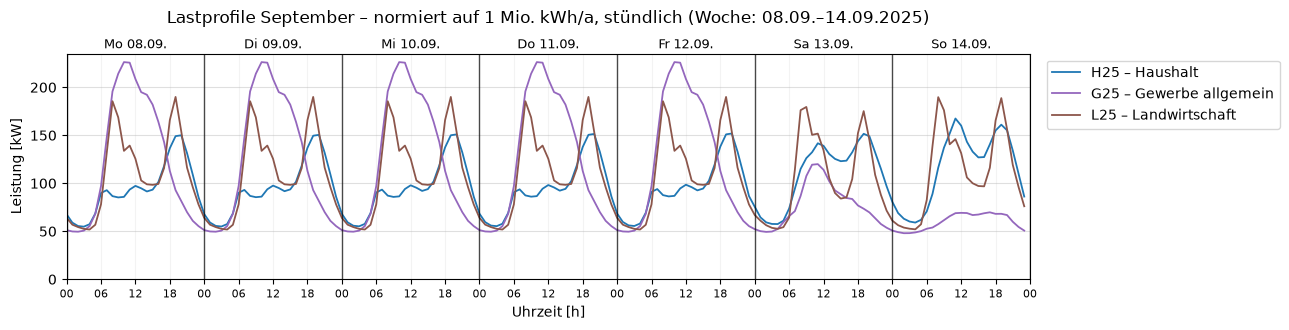

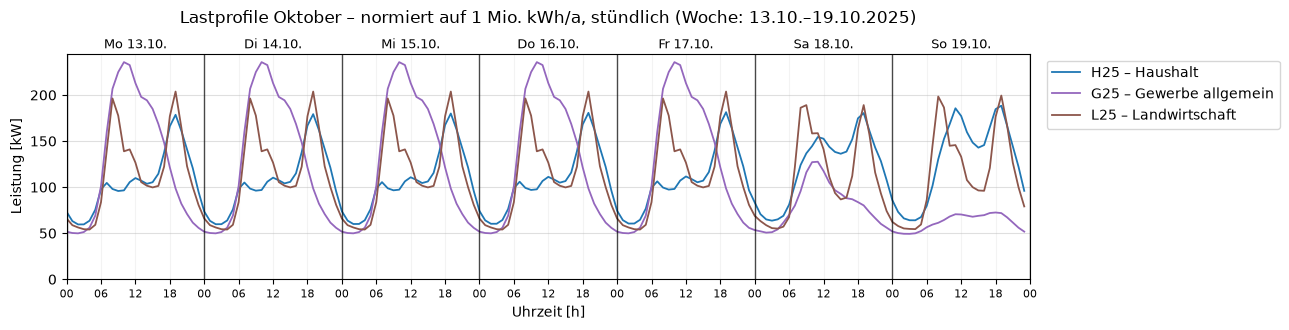

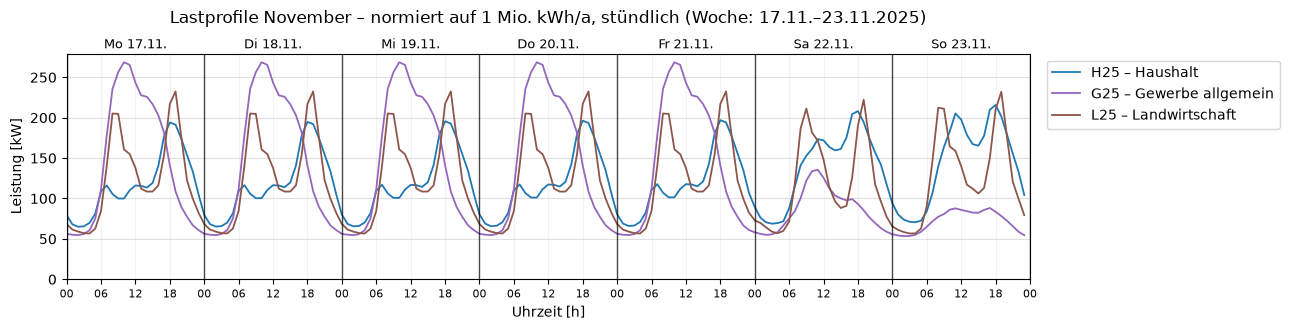

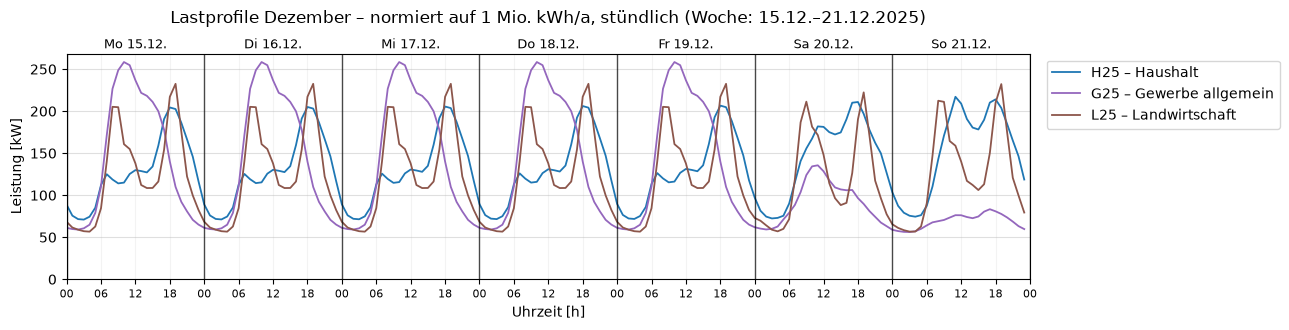

In [4]:
LOAD_PROFILES = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE, Lastprofil.LANDWIRTSCHAFT]

for month in Month:
    weeks = {p.label: pr.build_week(PROFILES, p, month, annual_kwh=pr.NORM_KWH, unit="kW",
                                    start=WEEK_STARTS[month], resolution="1h")
             for p in LOAD_PROFILES}
    first = next(iter(weeks.values()))
    plots.plot_load_week(weeks, f"Lastprofile {month.label} – normiert auf 1 Mio. kWh/a, stündlich "
                                f"(Woche: {first.index[0]:%d.%m.}–{first.index[-1]:%d.%m.%Y})")
    plt.show()

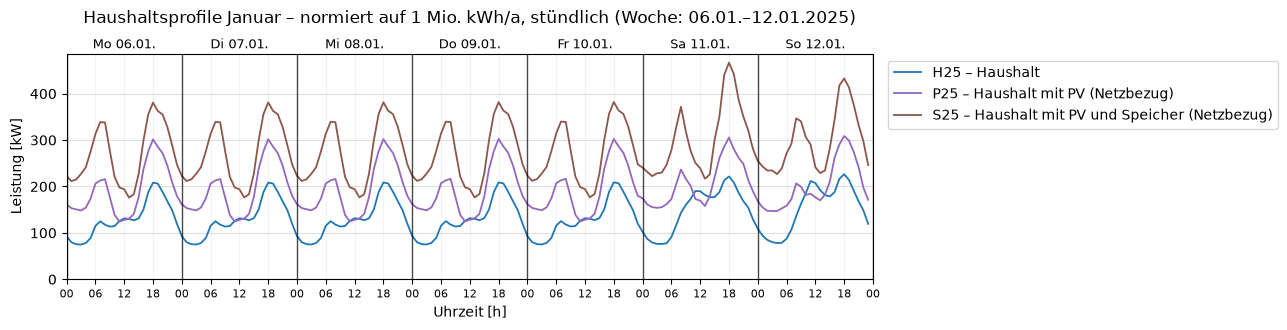

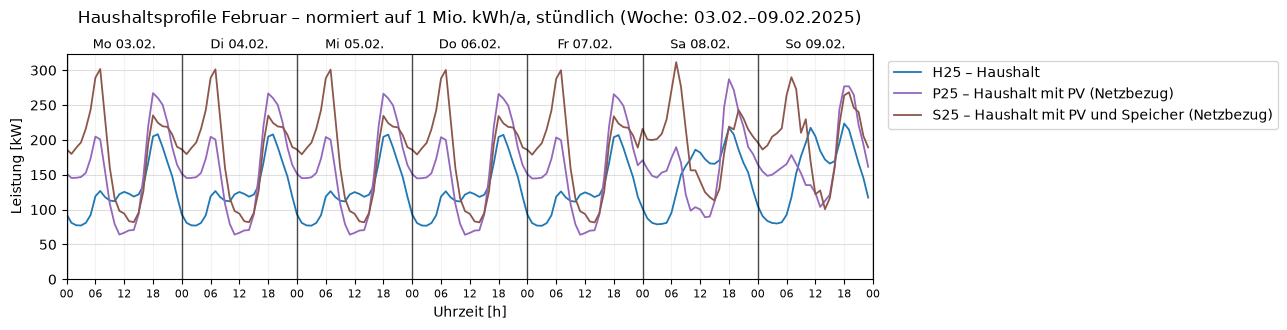

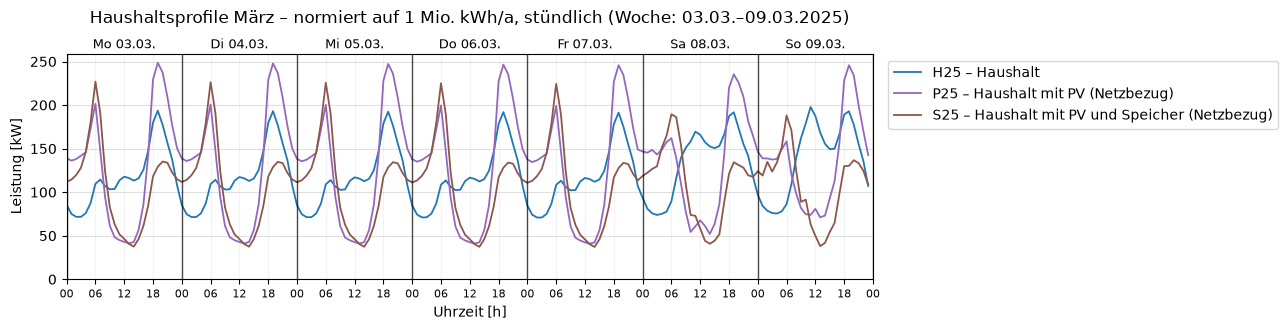

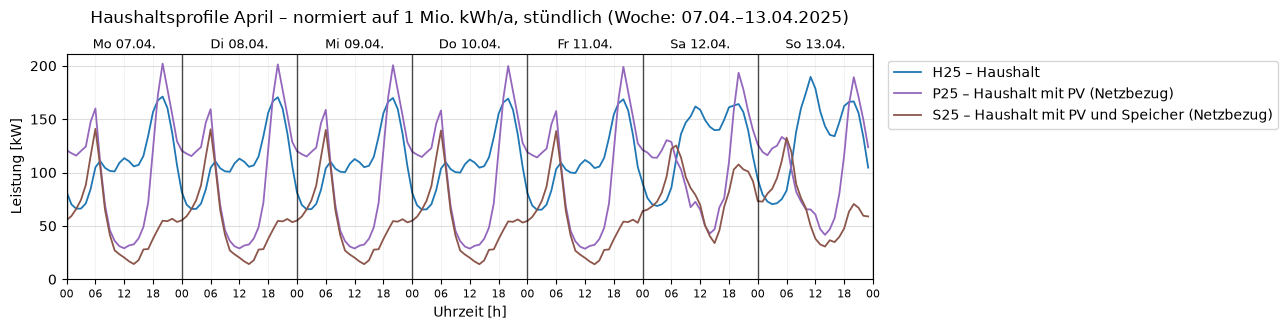

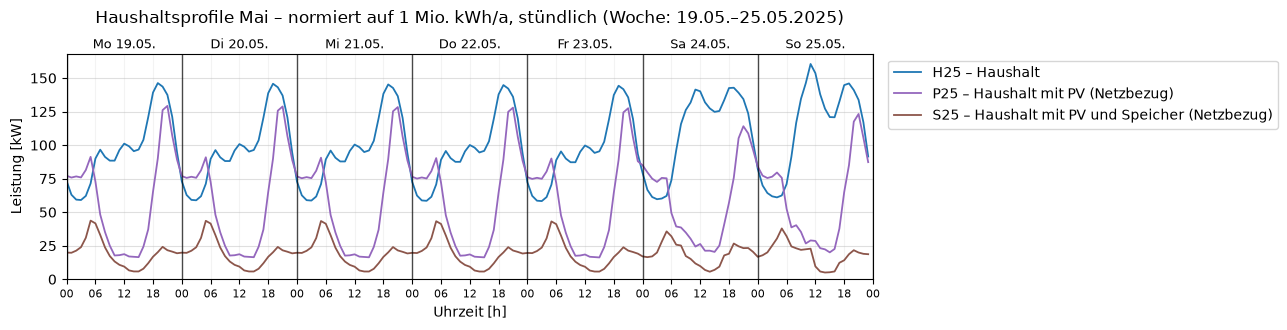

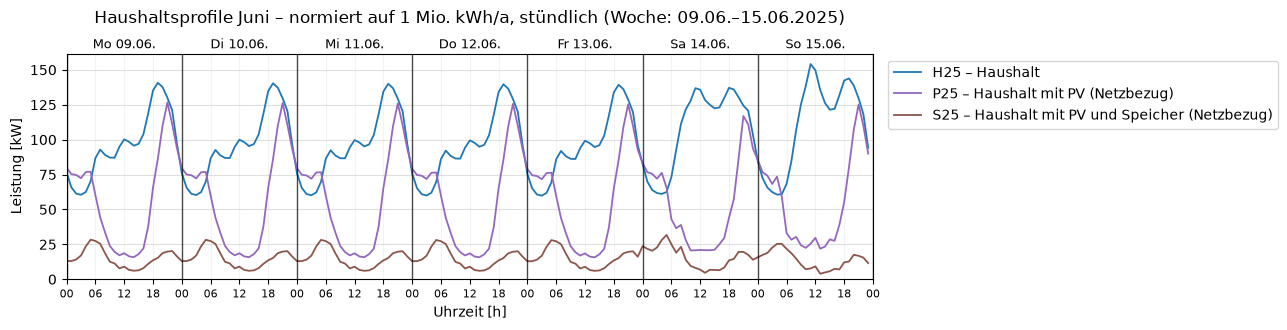

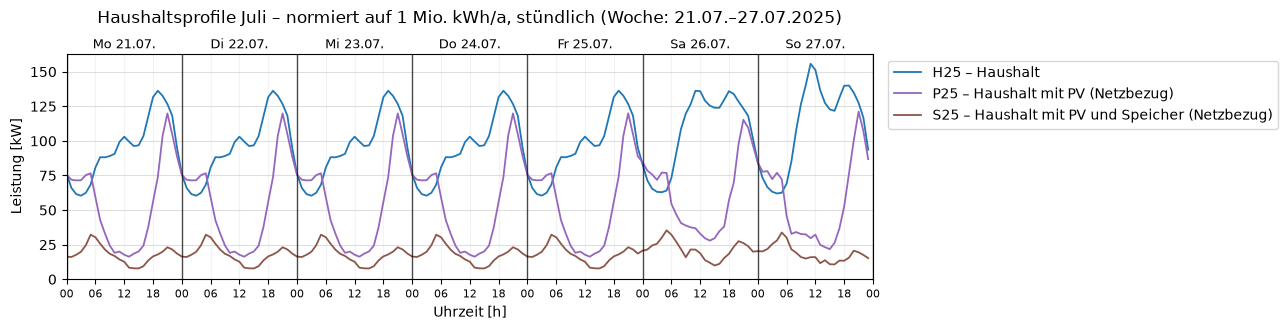

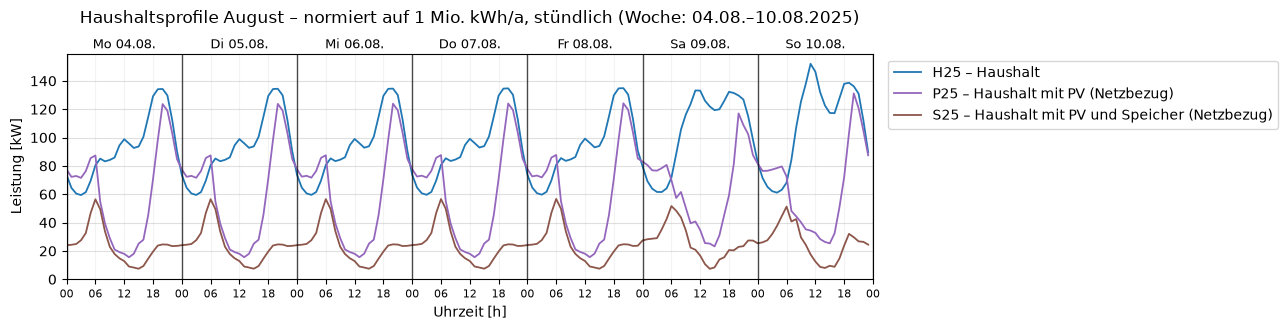

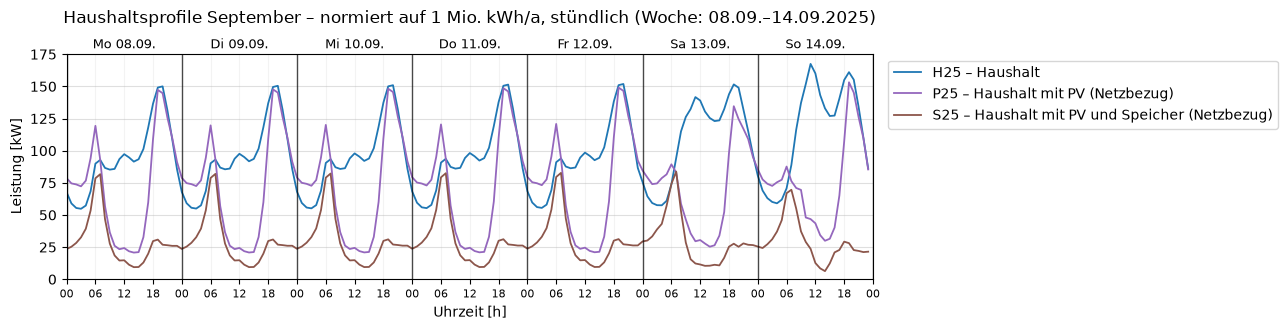

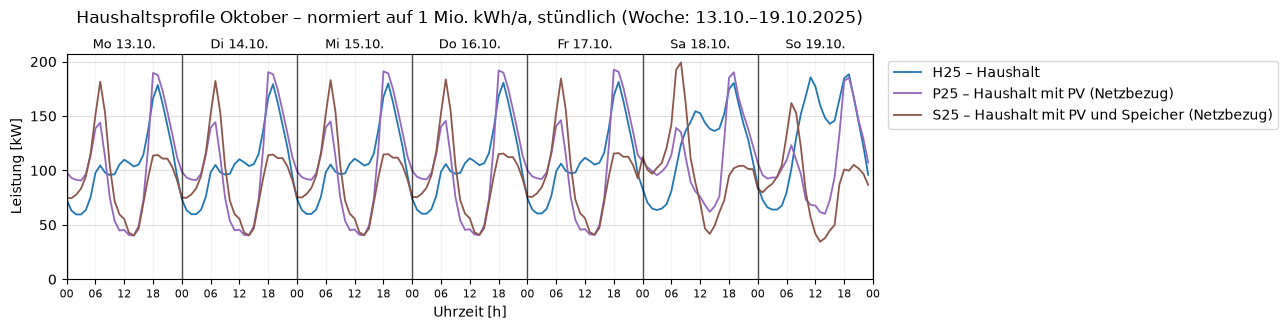

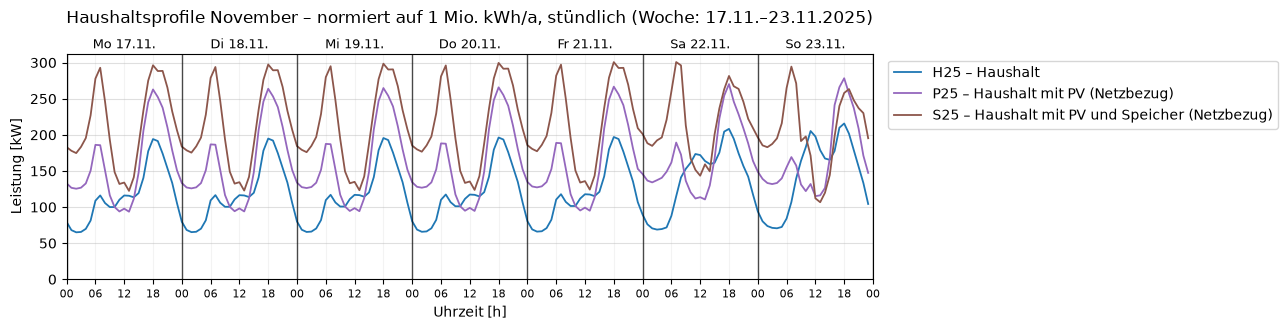

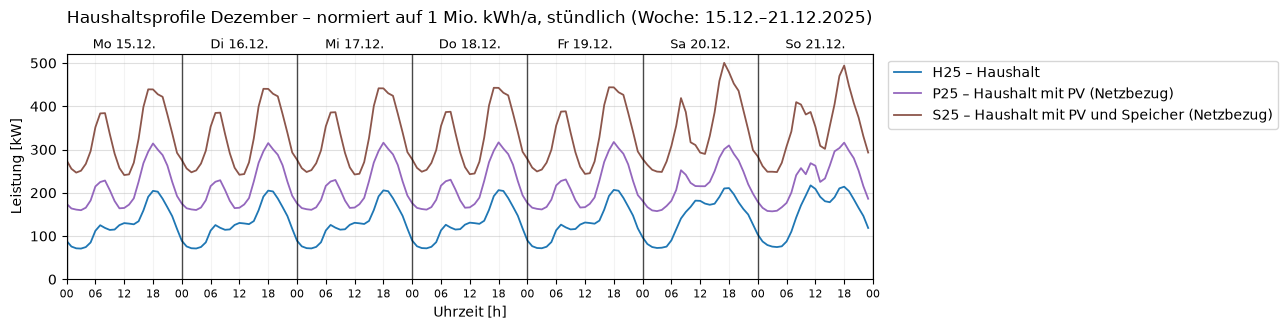

In [5]:
HAUSHALT_PROFILES = [Lastprofil.HAUSHALT, Lastprofil.HAUSHALT_PV, Lastprofil.HAUSHALT_PV_SPEICHER]

for month in Month:
    weeks = {p.label: pr.build_week(PROFILES, p, month, annual_kwh=pr.NORM_KWH, unit="kW",
                                    start=WEEK_STARTS[month], resolution="1h")
             for p in HAUSHALT_PROFILES}
    first = next(iter(weeks.values()))
    plots.plot_load_week(weeks, f"Haushaltsprofile {month.label} – normiert auf 1 Mio. kWh/a, stündlich "
                                f"(Woche: {first.index[0]:%d.%m.}–{first.index[-1]:%d.%m.%Y})")
    plt.show()

**Wochenenergie je Monat** (alle Profile normiert auf 1 Mio. kWh/a; ein Jahr hat 52,1 Wochen, im Mittel also etwa 19 200 kWh je Woche):

In [6]:
ALLE = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE, Lastprofil.LANDWIRTSCHAFT, Lastprofil.HAUSHALT_PV,
        Lastprofil.HAUSHALT_PV_SPEICHER]
energy = pd.DataFrame({
    p.label: [pr.build_week(PROFILES, p, m, start=WEEK_STARTS[m], resolution="1h").sum() for m in Month]
    for p in ALLE
}, index=[m.label for m in Month])
energy["G25/H25"] = energy.iloc[:, 1] / energy.iloc[:, 0]
energy["P25/H25"] = energy.iloc[:, 3] / energy.iloc[:, 0]
energy["S25/H25"] = energy.iloc[:, 4] / energy.iloc[:, 0]
energy.round(2)

,H25 – Haushalt,G25 – Gewerbe allgemein,L25 – Landwirtschaft,P25 – Haushalt mit PV (Netzbezug),S25 – Haushalt mit PV und Speicher (Netzbezug),G25/H25,P25/H25,S25/H25
Januar,22719.75,21518.05,20782.75,32767.69,46797.37,0.95,1.44,2.06
Februar,22299.51,21289.32,20782.75,26820.21,31521.64,0.95,1.20,1.41
März,20474.20,20684.52,20215.44,22071.24,18289.16,1.01,1.08,0.89
April,19315.88,19364.30,19080.82,17042.16,10010.49,1.00,0.88,0.52
Mai,16945.86,18328.34,18253.72,9937.55,3239.85,1.08,0.59,0.19
Juni,16707.49,18356.55,17426.28,9472.95,2527.31,1.10,0.57,0.15
Juli,16655.36,17388.90,17426.28,9451.46,3121.95,1.04,0.57,0.19
August,16270.44,17708.41,17426.28,10391.02,4137.09,1.09,0.64,0.25
September,16721.62,18225.32,18253.72,12243.38,5023.61,1.09,0.73,0.30
Oktober,18761.87,18857.81,19080.82,17741.53,15868.14,1.01,0.95,0.85


**Vergleich der Profile:**

- **H25 (Haushalt):** Morgen- und ausgeprägte Abendspitze (ca. 18–20 Uhr), am Wochenende höherer Verbrauch über den Tag. Durch die Dynamisierung ist der Verbrauch im Winter deutlich höher als im Sommer.
- **G25 (Gewerbe):** hohe Leistung an Werktagen während der Betriebszeiten (etwa 7–17 Uhr, Maximum vormittags), deutlich niedrigere Leistung nachts, samstags und vor allem sonntags. Der Jahresgang ist schwächer, weil keine Dynamisierung angewendet wird.
- **L25 (Landwirtschaft):** Tagesgang mit Morgenspitze gegen 8–9 Uhr und Abendspitze gegen 19 Uhr, kaum Unterschied zwischen Werktag, Samstag und Sonntag; der Jahresgang ist ähnlich schwach wie bei G25 (Wochenenergie 0,91 bis 1,09 × H25).
- **P25 (Haushalt mit PV):** Tagsüber deckt die PV-Anlage einen großen Teil des Verbrauchs; im Sommer sinkt der Netzbezug mittags auf etwa ein Viertel des nächtlichen Werts, die Abendspitze bleibt. Weil das Profil auf 1 Mio. kWh **Netzbezug** normiert ist, verschiebt sich die Energie in den Winter: Im Juli liegt die Wochenenergie bei 0,57 × H25, im Dezember bei 1,63 × H25.
- **S25 (Haushalt mit PV und Speicher):** Der Speicher deckt zusätzlich den Abend und die Nacht; im Sommer bleibt nur ein geringer Netzbezug (Juli 0,19 × H25), fast der ganze Bezug fällt im Winter an (Dezember 2,49 × H25).
- Die Lastspitzen fallen zeitlich auseinander: Gewerbe tagsüber, Haushalte abends. Gewerbelasten fallen damit zeitlich besser mit der PV-Erzeugung zusammen als Haushaltslasten.

**Skalierung über die Jahreshöchstleistung:** In der Simulationssoftware wird jede Last über ihre höchste Stundenleistung im Jahr skaliert (Task 3). Die Tabelle zeigt die Jahreshöchstleistung je 1 Mio. kWh und den Jahresverbrauch, der sich bei gleicher Höchstleistung ergibt (bezogen auf H25). Ein Haushalt mit PV bezieht bei gleicher Winter-Abendspitze etwa 30 % weniger Energie aus dem Netz, ein Haushalt mit PV und Speicher etwa 55 % weniger.

In [7]:
import timeseries as tsm
from elements import Profile

spitzen = pd.DataFrame({"Jahreshöchstleistung [kW je 1 Mio. kWh]": {
    p.value: tsm.annual_peak_mw_per_kwh(p) * 1e9 for p in
    [Profile.HAUSHALT, Profile.GEWERBE, Profile.LANDWIRTSCHAFT, Profile.HAUSHALT_PV, Profile.HAUSHALT_PV_SPEICHER]}})
spitzen["Jahresverbrauch bei gleicher Höchstleistung (H25 = 1)"] = (
    spitzen.iloc[0, 0] / spitzen.iloc[:, 0])
spitzen.round(2)

,Jahreshöchstleistung [kW je 1 Mio. kWh],Jahresverbrauch bei gleicher Höchstleistung (H25 = 1)
Haushalt (BDEW H25),226.64,1.00
Gewerbe (BDEW G25),272.12,0.83
Landwirtschaft (BDEW L25),232.52,0.97
"Haushalt mit PV, Netzbezug (BDEW P25)",326.38,0.69
"Haushalt mit PV und Speicher, Netzbezug (BDEW S25)",508.91,0.45


### 1.2 Windenergieanlage (Vestas V90-2.0 MW)

**Anlagendaten** [7]: Nennleistung 2,0 MW, Rotordurchmesser 90 m (überstrichene Fläche A ≈ 6 362 m²), Nabenhöhen 80 / 95 / 105 m, Einschaltgeschwindigkeit 4 m/s, Nenngeschwindigkeit 13 m/s, Abschaltgeschwindigkeit 25 m/s. Verwendet wird eine Nabenhöhe von 105 m.

**Physikalischer Hintergrund:** Die im Wind enthaltene Leistung, die durch die Rotorfläche strömt, ist

P_Wind = ½ · ρ · A · v³

mit der Luftdichte ρ ≈ 1,225 kg/m³. Eine Windenergieanlage kann davon nur den Anteil c_p (Leistungsbeiwert) entnehmen; theoretisch höchstens c_p,Betz = 16/27 ≈ 0,59 [9]. Real erreichte Werte und die Regelung der Anlage sind in der **Leistungskennlinie** P(v) zusammengefasst, die der Hersteller für eine Standard-Luftdichte angibt. Sie hat vier Bereiche [9]:

| Bereich | Windgeschwindigkeit | Leistung |
|---|---|---|
| Stillstand | v < v_ein | 0 |
| Teillast | v_ein ≤ v < v_Nenn | steigt etwa mit v³ |
| Volllast | v_Nenn ≤ v < v_ab | Nennleistung (Pitch-Regelung begrenzt die Leistung) |
| Sturmabschaltung | v ≥ v_ab = 25 m/s | 0 |

**Kennlinie:** Die Stützstellen (Schrittweite 0,5 m/s) stammen aus der Turbinendatenbank der Open Energy Database (OEDB), die mit der Python-Bibliothek *windpowerlib* ausgeliefert wird; als Quelle ist dort die oben genannte Herstellerangabe auf wind-turbine-models.com eingetragen [8]. Zwischen den Stützstellen wird linear interpoliert. Die Tabelle beginnt bereits bei 3,5 m/s mit 42 kW, während [7] eine Einschaltgeschwindigkeit von 4 m/s nennt. Oberhalb von 12,5 m/s wird die Nennleistung von 2 000 kW angesetzt.

**Höhenumrechnung:** Die Windgeschwindigkeit nimmt mit der Höhe zu. Die API liefert sie in 100 m Höhe; auf die Nabenhöhe h wird mit dem Potenzgesetz umgerechnet [9]:

v_Nabe = v_100 · (h / 100 m)^α, &nbsp; α = 1/7

Bei h = 105 m ergibt sich ein Faktor von 1,007. Der Einfluss ist also gering.

**Vereinfachungen:** keine Korrektur der Luftdichte (Temperatur, Höhe), keine Verfügbarkeitsverluste, keine Abschattung durch andere Anlagen, Stundenwerte statt Böen.

**Normierung:** Neben der Leistung in kW wird die Leistung bezogen auf die Nennleistung gespeichert (`wind_pu`). Damit lässt sich die Zeitreihe auch auf andere Anlagengrößen übertragen. Bei der Einbindung ins Netz kann die Zeitreihe so auf die jeweilige Anlagengröße skaliert werden.

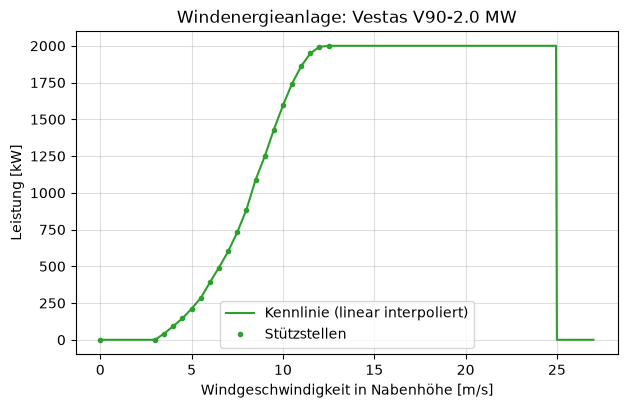

In [8]:
wt.plot_wind_curve()
plt.show()

### 1.3 PV-Anlage (Trina Solar Vertex S+ 460 W)

**Moduldaten:** Trina Solar Vertex S+ TSM-NEG9RC.27, bifaziales Glas-Glas-Modul (n-Typ, i-TOPCon), 144 Halbzellen, 1762 × 1134 mm (2,0 m²).

| Kenngröße | Wert | Quelle |
|---|---|---|
| Nennleistung P_STC (1000 W/m², 25 °C Zelltemperatur) | 460 W | [10] |
| Modulwirkungsgrad | 23,0 % | [10] |
| Temperaturkoeffizient von P_max (γ) | −0,29 %/K | [11] |
| NOCT (800 W/m², 20 °C Luft, 1 m/s Wind) | 43 °C | [11] |

Das Datenblatt [11] listet die Leistungsklassen 425–450 W; die Temperaturkennwerte gelten für die gesamte Modellfamilie und werden für die 460-W-Klasse übernommen.

**Umrechnung Einstrahlung → Leistung:**

1. *Einstrahlung auf die Modulebene:* Die API liefert direkt die Globalstrahlung auf die geneigte Fläche G (35°, Süd), sodass keine eigene Umrechnung von horizontaler auf geneigte Fläche nötig ist [6].
2. *Zelltemperatur* nach dem NOCT-Modell [12]:

   T_Zelle = T_Luft + (NOCT − 20 °C) / (800 W/m²) · G

3. *Leistung:* Die Modulleistung ist näherungsweise proportional zur Einstrahlung und nimmt mit steigender Zelltemperatur linear ab [12]:

   P_AC = P_STC · (G / 1000 W/m²) · [1 + γ · (T_Zelle − 25 °C)] · η_System

   mit η_System = 0,86 für Verluste in Wechselrichter, Leitungen, durch Verschmutzung und Fehlanpassung (Annahme; die Temperaturverluste sind bereits im Term mit γ enthalten).

**Beispiel:** Bei G = 1000 W/m² und 25 °C Lufttemperatur ist T_Zelle ≈ 53,8 °C und P_AC ≈ 363 W je Modul (0,79 kW/kWp).

**Vereinfachungen:** kein bifazialer Mehrertrag von der Rückseite, keine Verschattung, kein verändertes Verhalten bei schwacher Einstrahlung, keine Leistungsbegrenzung durch den Wechselrichter.

**Normierung:** Die Leistung wird je Modul (`pv_module_w`) und je kWp installierter Leistung (`pv_kw_per_kwp`) gespeichert. Eine Anlage mit z. B. 22 Modulen hat 22 × 0,46 kW = 10,12 kWp; ihre Leistung ist `pv_kw_per_kwp` × 10,12 kW.

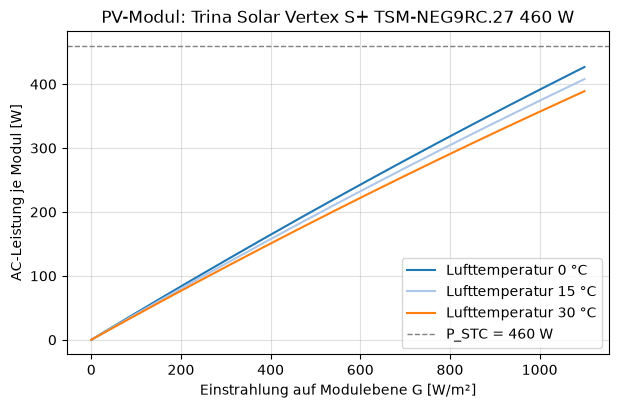

In [9]:
wt.plot_pv_curve()
plt.show()

### 1.4 Wetterdaten (Open-Meteo)

**Herkunft:** Die Wetterdaten stammen aus der *Historical Weather API* von Open-Meteo [4], [6]. Sie beruht auf Reanalyse-Datensätzen, in denen Messungen von Wetterstationen, Satelliten, Flugzeugen und Bojen mit einem numerischen Wettermodell zu einem lückenlosen Gitterdatensatz verbunden werden, unter anderem ERA5 des europäischen Wetterdienstes ECMWF [5].

**Abruf:** Standort 51,2° N, 7,34° E (Bergisches Land, NRW), Jahr 2025, stündliche Werte:

| Variable | Einheit | Bedeutung | Verwendung |
|---|---|---|---|
| `global_tilted_irradiance` | W/m² | Globalstrahlung auf eine geneigte Fläche (35° Neigung, Ausrichtung Süd), Mittel der vorangegangenen Stunde | PV |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe, Momentanwert | PV (Zelltemperatur) |
| `wind_speed_100m` | m/s | Windgeschwindigkeit in 100 m Höhe, Momentanwert | Wind |
| `shortwave_radiation` | W/m² | Globalstrahlung auf die horizontale Fläche | nur zur Information |

**Aufbereitung:**

1. Die API liefert Zeitstempel in UTC. Sie werden in lokale Zeit (Europe/Berlin) umgerechnet. Die Einstrahlung bezieht sich auf die vorangegangene Stunde und wird um eine Stunde verschoben, sodass alle Zeitstempel den Beginn der Stunde bezeichnen [6].
2. Aus den Wetterdaten wird über die Kennlinien die Leistung von PV und Wind berechnet (siehe unten).
3. **Typische Woche:** Für jeden Monat werden alle Wochen (Mo–So) betrachtet, die vollständig im Monat liegen, keine Zeitumstellung und keinen Feiertag enthalten. Gewählt wird die Woche, deren mittlere PV-Leistung und mittlere Windleistung zusammen am wenigsten vom Monatsmittel abweichen (Summe der relativen Abweichungen). So wird weder eine außergewöhnlich sonnige noch eine windstille Woche ausgewählt.
4. Ergebnis und Rohdaten werden als CSV gespeichert (`data/weather_weeks_2025.csv`, `data/weather_raw_2025.csv`).

**Tabelle der typischen Wochen** (erste Zeilen der Datei `weather_weeks_2025.csv`):

In [10]:
weather_table = pd.read_csv(WEATHER_FILE, index_col="time", parse_dates=True)
print(f"{len(weather_table)} Zeilen (12 Wochen × 168 Stunden), {weather_table.shape[1]} Spalten")
weather_table.head(10)

2016 Zeilen (12 Wochen × 168 Stunden), 10 Spalten


,month,hour_of_week,temperature_2m,global_tilted_irradiance,wind_speed_100m,wind_speed_hub,pv_module_w,pv_kw_per_kwp,wind_kw,wind_pu
time,,,,,,,,,,
2025-01-06 00:00:00,JANUARY,0,7.05,0.0000,11.7466,11.8288,0.0000,0.0000,1977.8195,0.9889
2025-01-06 01:00:00,JANUARY,1,7.15,0.0000,12.0354,12.1195,0.0000,0.0000,1994.9019,0.9975
2025-01-06 02:00:00,JANUARY,2,8.70,0.0000,11.6010,11.6821,0.0000,0.0000,1964.5629,0.9823
2025-01-06 03:00:00,JANUARY,3,8.55,0.0000,11.2695,11.3484,0.0000,0.0000,1921.7454,0.9609
2025-01-06 04:00:00,JANUARY,4,8.40,0.0000,11.6813,11.7630,0.0000,0.0000,1971.8745,0.9859
2025-01-06 05:00:00,JANUARY,5,8.20,0.0000,11.5412,11.6220,0.0000,0.0000,1959.1246,0.9796
2025-01-06 06:00:00,JANUARY,6,8.10,0.0000,12.6646,12.7532,0.0000,0.0000,2000.0000,1.0000
2025-01-06 07:00:00,JANUARY,7,8.15,0.0000,13.1477,13.2397,0.0000,0.0000,2000.0000,1.0000
2025-01-06 08:00:00,JANUARY,8,8.30,0.0000,13.6401,13.7355,0.0000,0.0000,2000.0000,1.0000


| Spalte | Einheit | Bedeutung |
|---|---|---|
| `time` | – | Beginn der Stunde, lokale Zeit (MEZ/MESZ) |
| `month`, `hour_of_week` | – | Monat (Enum `Month`), Stunde der Woche 0 … 167 (Mo 00:00 = 0) |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe |
| `global_tilted_irradiance` | W/m² | Einstrahlung auf die Modulebene (35°, Süd) |
| `wind_speed_100m`, `wind_speed_hub` | m/s | Windgeschwindigkeit in 100 m bzw. Nabenhöhe (105 m) |
| `pv_module_w` | W | AC-Leistung eines PV-Moduls (460 W) |
| `pv_kw_per_kwp` | kW/kWp | AC-Leistung je kWp |
| `wind_kw` | kW | Leistung der V90-2.0 MW |
| `wind_pu` | – | Leistung bezogen auf die Nennleistung |

In [11]:
def stats(series, *which):
    funcs = {"min": series.min, "Mittel": series.mean, "max": series.max}
    return [funcs[k]() for k in which]

rows = {}
for month, df in WEATHER.items():
    g_day_max = df["global_tilted_irradiance"].resample("D").max()      # Tageshöchstwert der Einstrahlung
    rows[month.label] = {
        ("Woche", "ab"): df.index[0].strftime("%a %d.%m.%Y"),
        **dict(zip([("T_Luft [°C]", k) for k in ("min", "Mittel", "max")],
                   stats(df["temperature_2m"], "min", "Mittel", "max"))),
        ("G_Modul [W/m²]", "Mittel"): df["global_tilted_irradiance"].mean(),
        ("G_Modul [W/m²]", "Tagesmax. min"): g_day_max.min(),
        ("G_Modul [W/m²]", "max"): g_day_max.max(),
        **dict(zip([("Wind Nabe [m/s]", k) for k in ("min", "Mittel", "max")],
                   stats(df["wind_speed_hub"], "min", "Mittel", "max"))),
        ("PV-Modul [W]", "Mittel"): df["pv_module_w"].mean(),
        ("PV-Modul [W]", "max"): df["pv_module_w"].max(),
        ("PV-Modul [W]", "Energie [kWh/Woche]"): df["pv_module_w"].sum() / 1000,
        **dict(zip([("WEA [MW]", k) for k in ("min", "Mittel", "max")],
                   [v / 1000 for v in stats(df["wind_kw"], "min", "Mittel", "max")])),
        ("WEA [MW]", "Energie [MWh/Woche]"): df["wind_kw"].sum() / 1000,
        ("WEA [MW]", "Stunden Stillstand"): int((df["wind_kw"] <= 0).sum()),
    }
overview = pd.DataFrame(rows).T
overview.columns = pd.MultiIndex.from_tuples(overview.columns)
num = overview.columns.drop(("Woche", "ab"))
overview[num] = overview[num].astype(float)
plots.table(overview, decimals=1, int_cols=[("WEA [MW]", "Stunden Stillstand")])

Zur Tabelle: Die Einstrahlung ist nachts immer 0 W/m², ein Minimum über die Woche sagt deshalb nichts aus. Stattdessen steht unter **Tagesmax. min** der höchste Wert des trübsten Tages und unter **max** der höchste Wert des sonnigsten Tages. Bei der WEA zählt **Stunden Stillstand** die Stunden mit einer Windgeschwindigkeit unter der Einschaltgeschwindigkeit (4 m/s), in denen die Anlage keine Leistung abgibt. Die Leistungswerte gelten für ein PV-Modul (460 W) bzw. eine WEA (2,0 MW). Im CIGRE-Netz werden sie mit der installierten Leistung skaliert (siehe 3.2).

**Wetterdiagramme:** Für jeden Monat zeigt ein zweiteiliges Diagramm die typische Woche:

- **oben:** Windgeschwindigkeit in Nabenhöhe [m/s], Lufttemperatur [°C] und Einstrahlung auf die Modulebene [100 W/m²]
- **unten:** Leistung der Windenergieanlage [MW] und eines PV-Moduls [100 W]

Die Einstrahlung und die PV-Leistung sind so skaliert, dass alle Größen im selben Zahlenbereich liegen: Ein Wert von 2 im unteren Diagramm entspricht 2 MW der Windenergieanlage bzw. 200 W des PV-Moduls, ein Wert von 8 im oberen Diagramm entspricht 800 W/m² Einstrahlung.

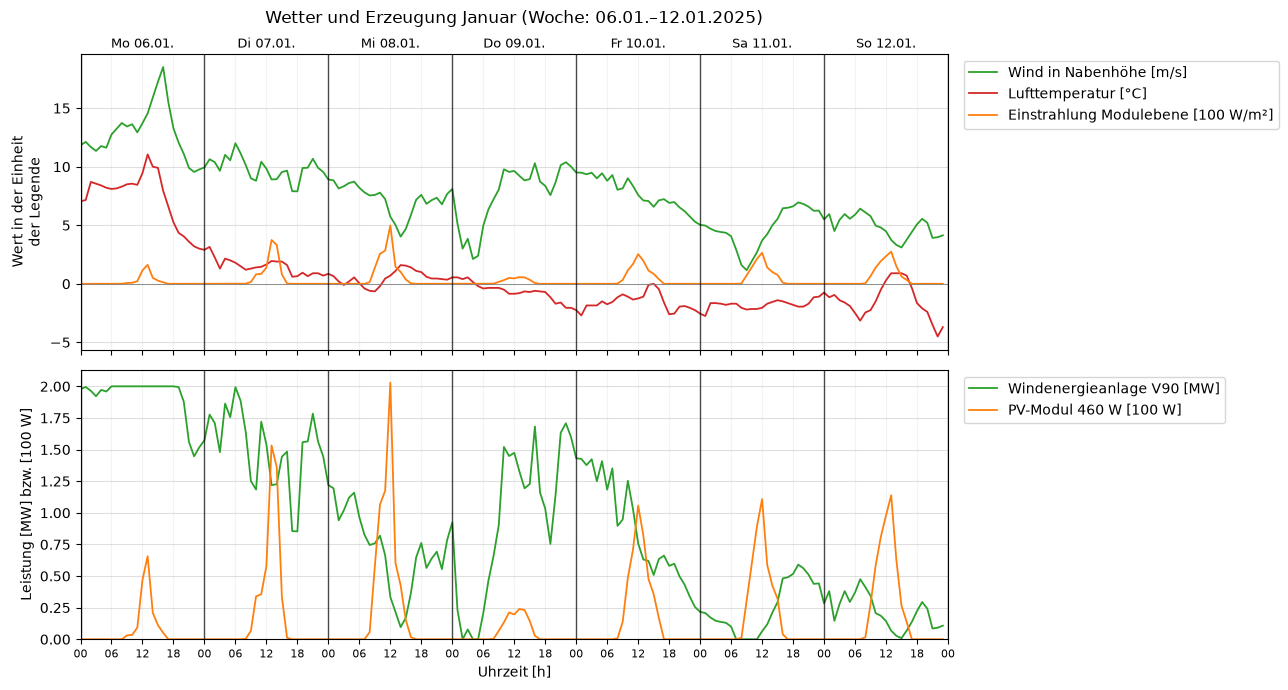

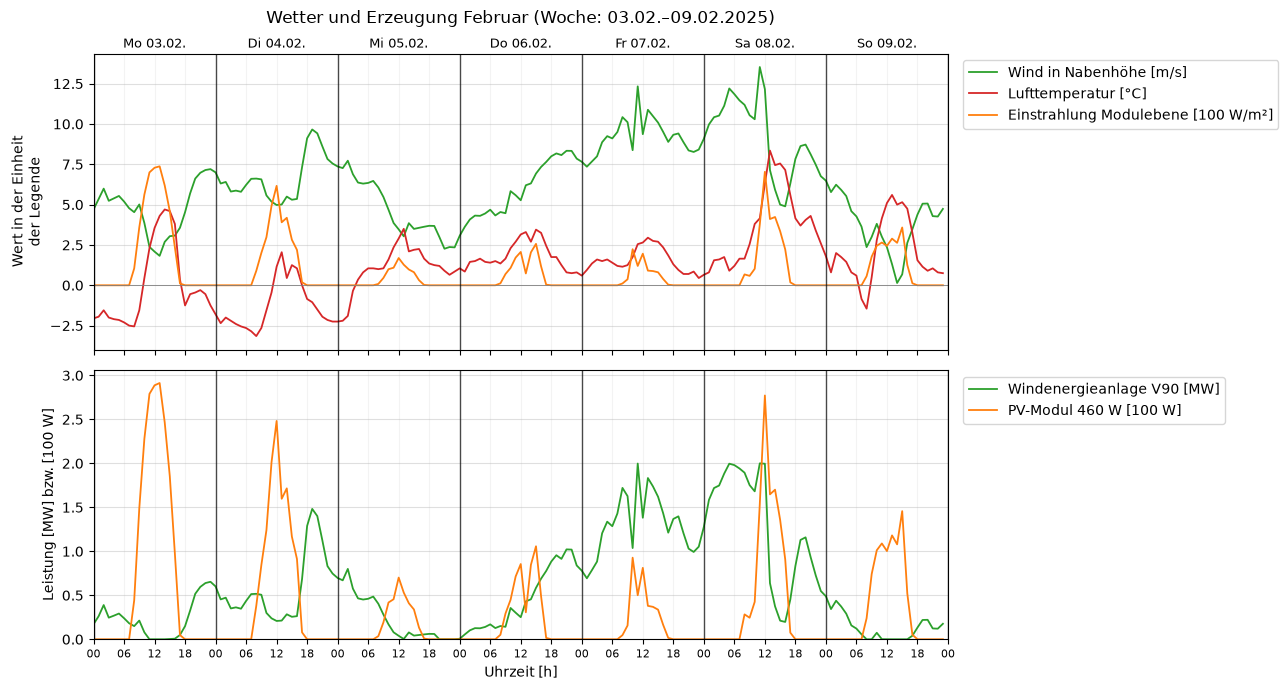

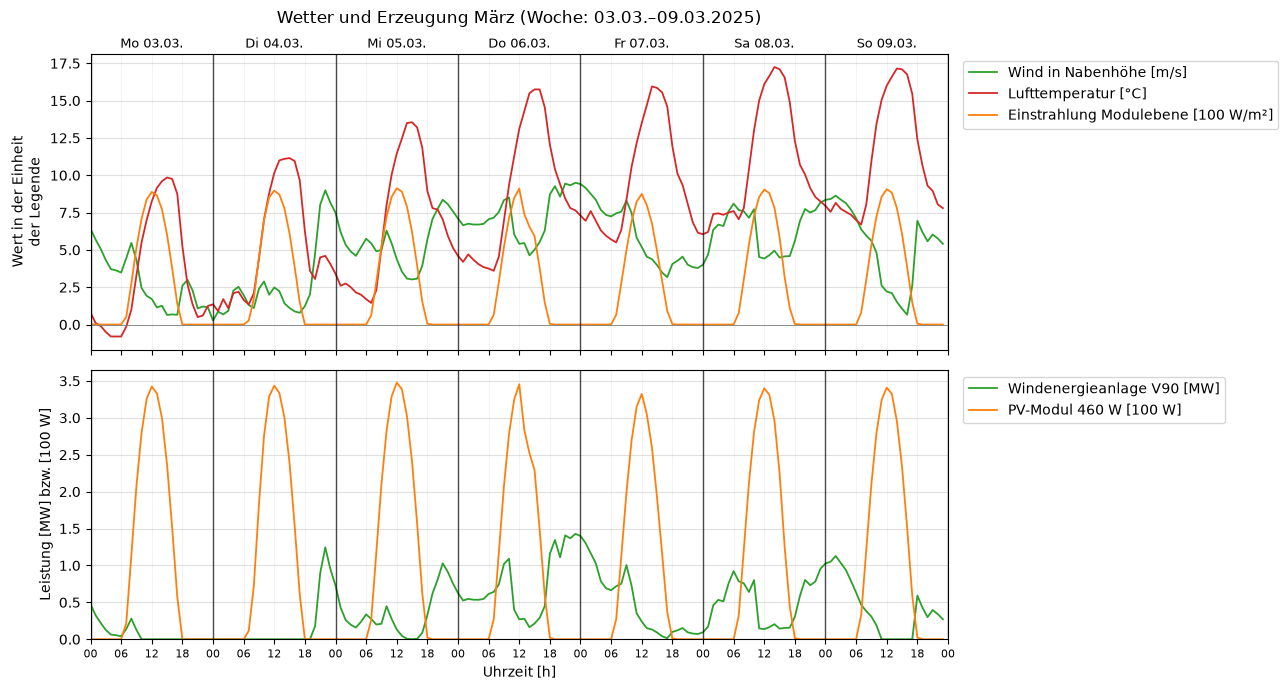

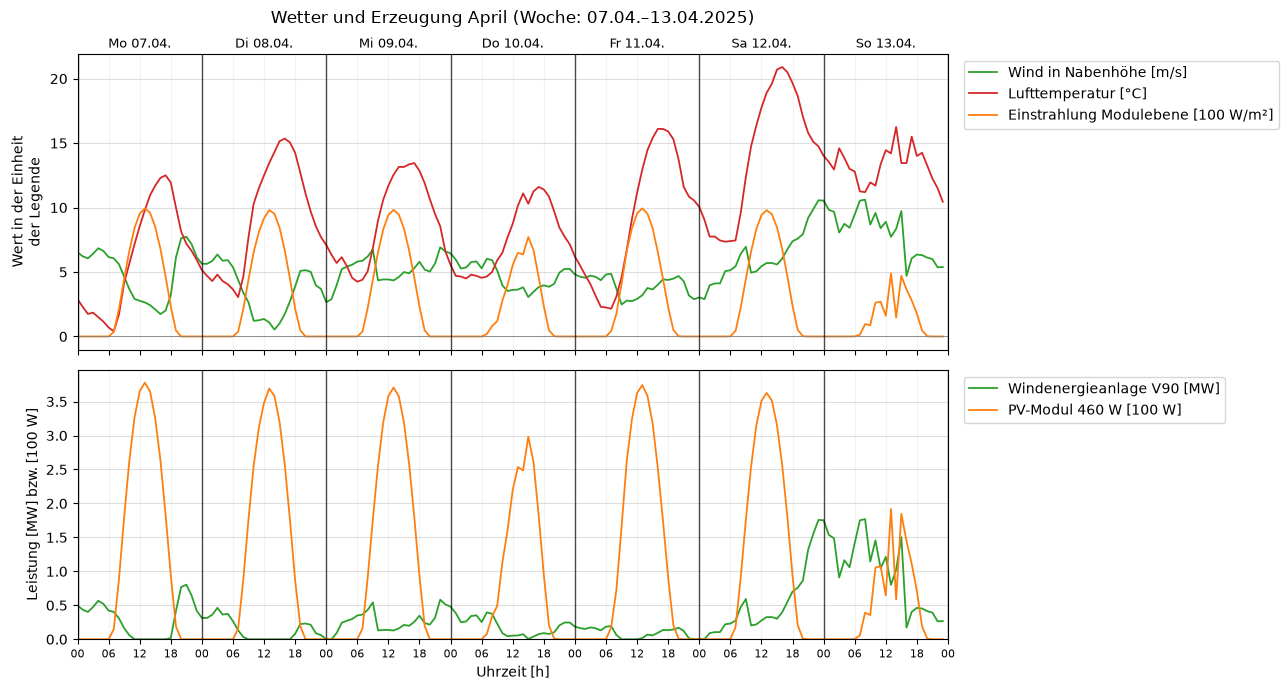

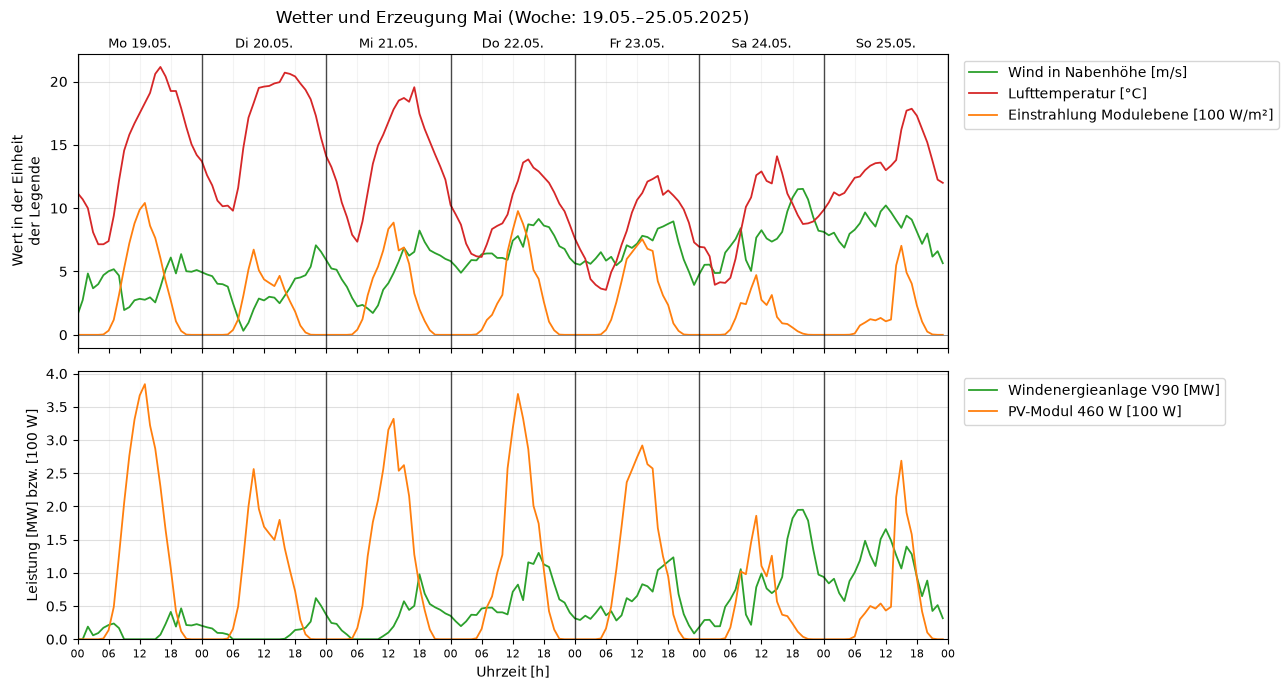

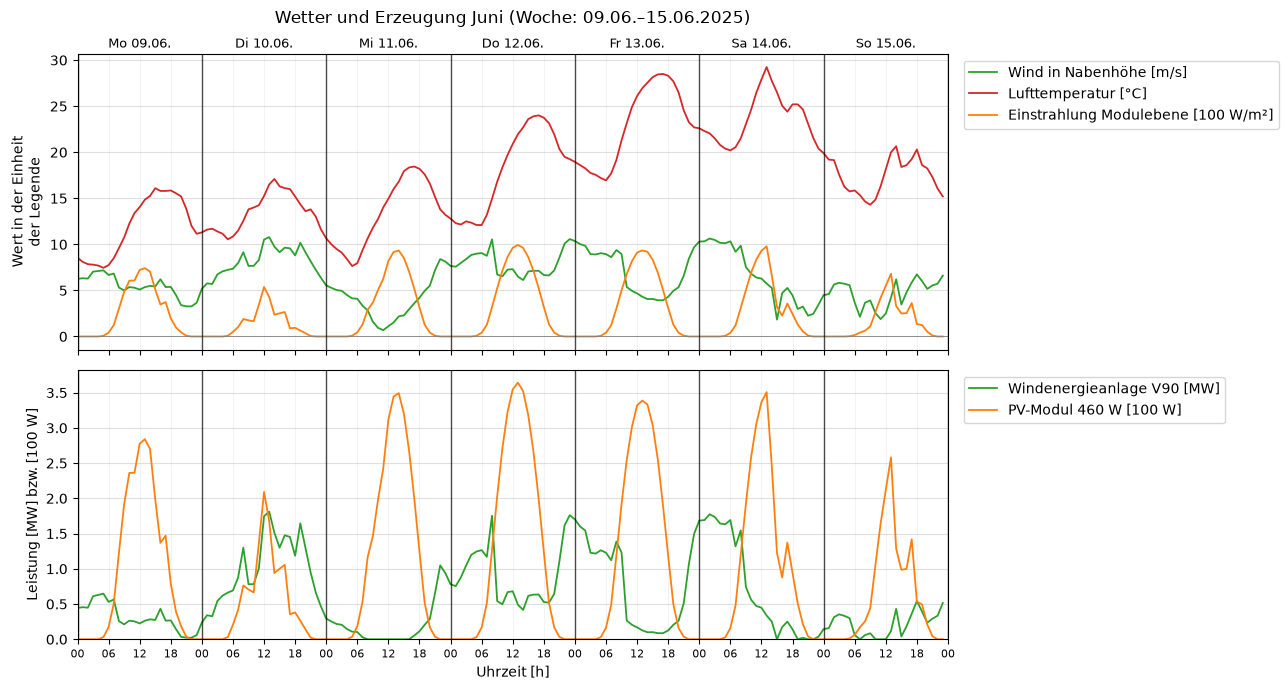

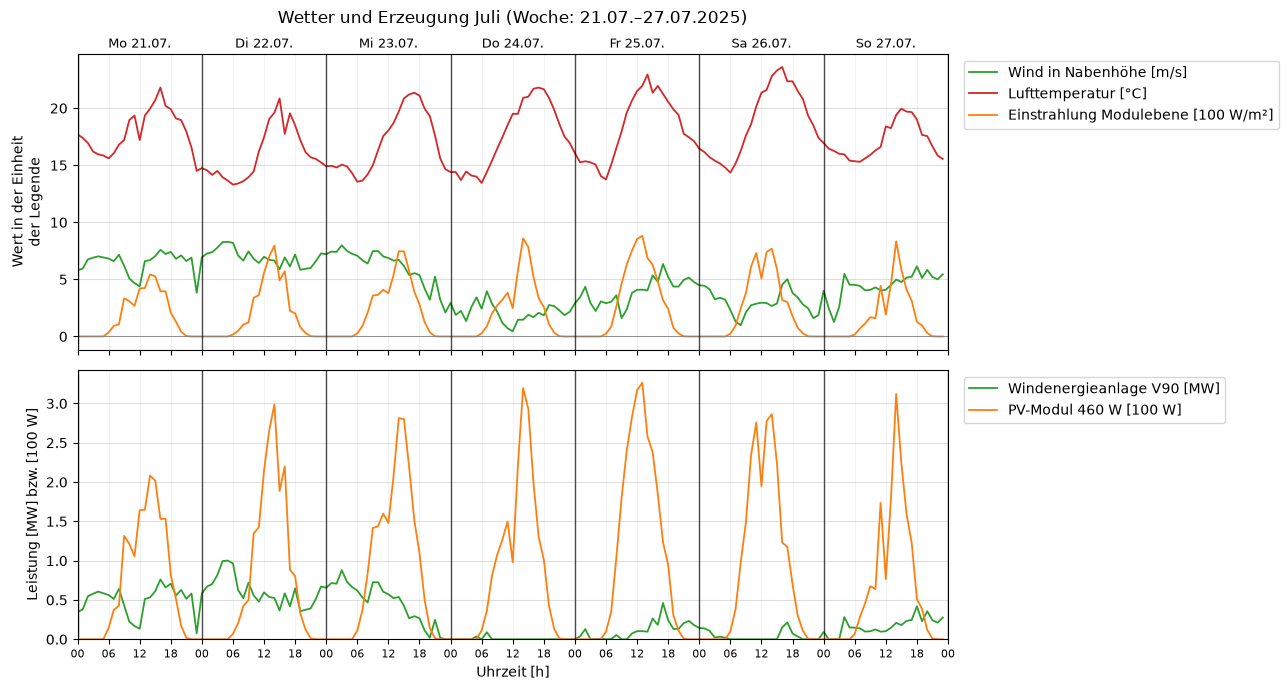

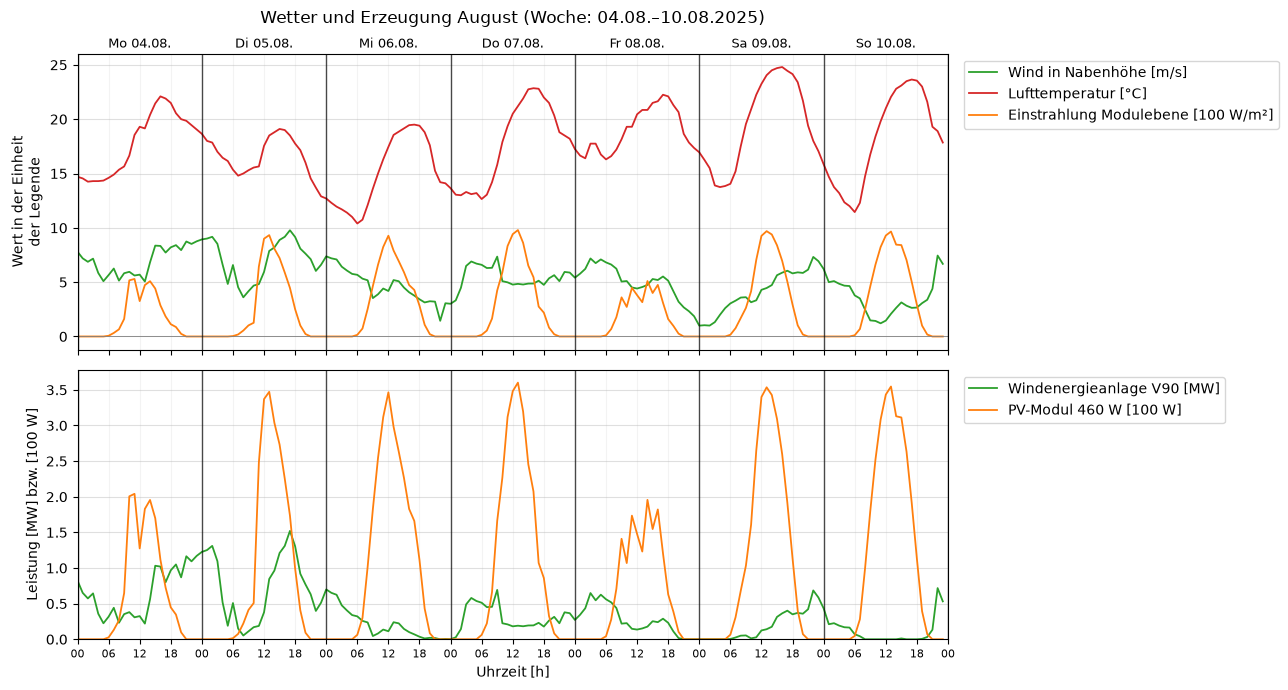

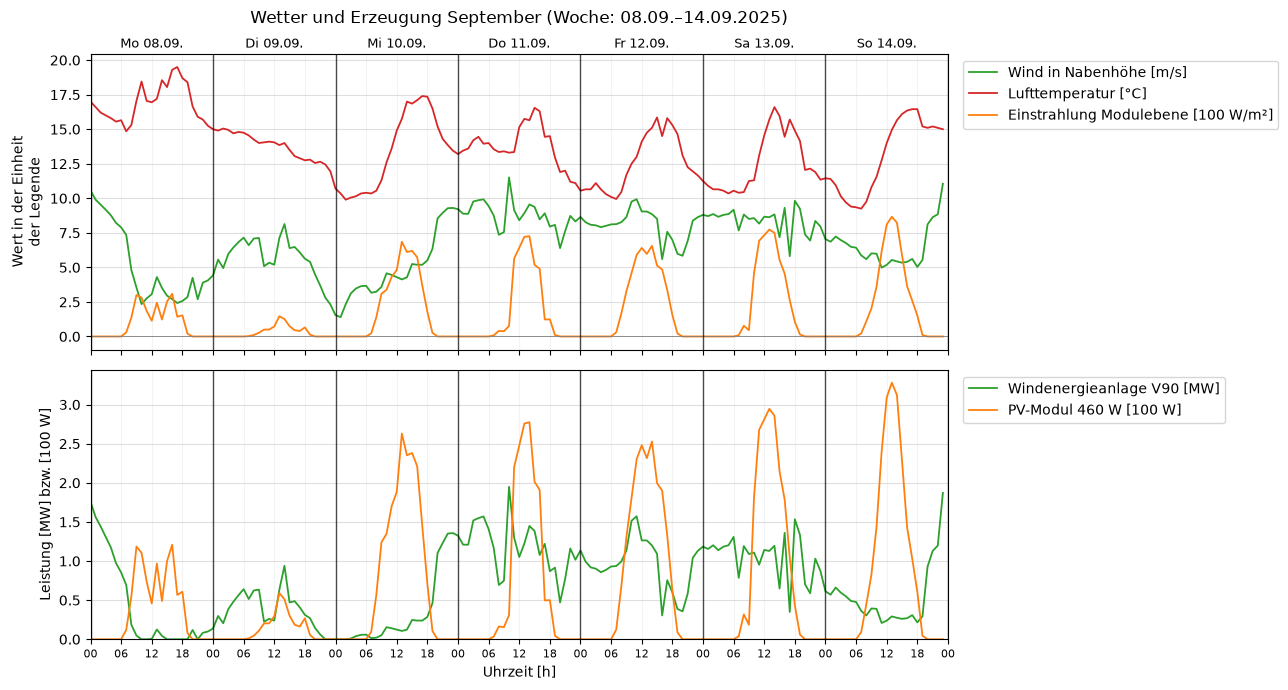

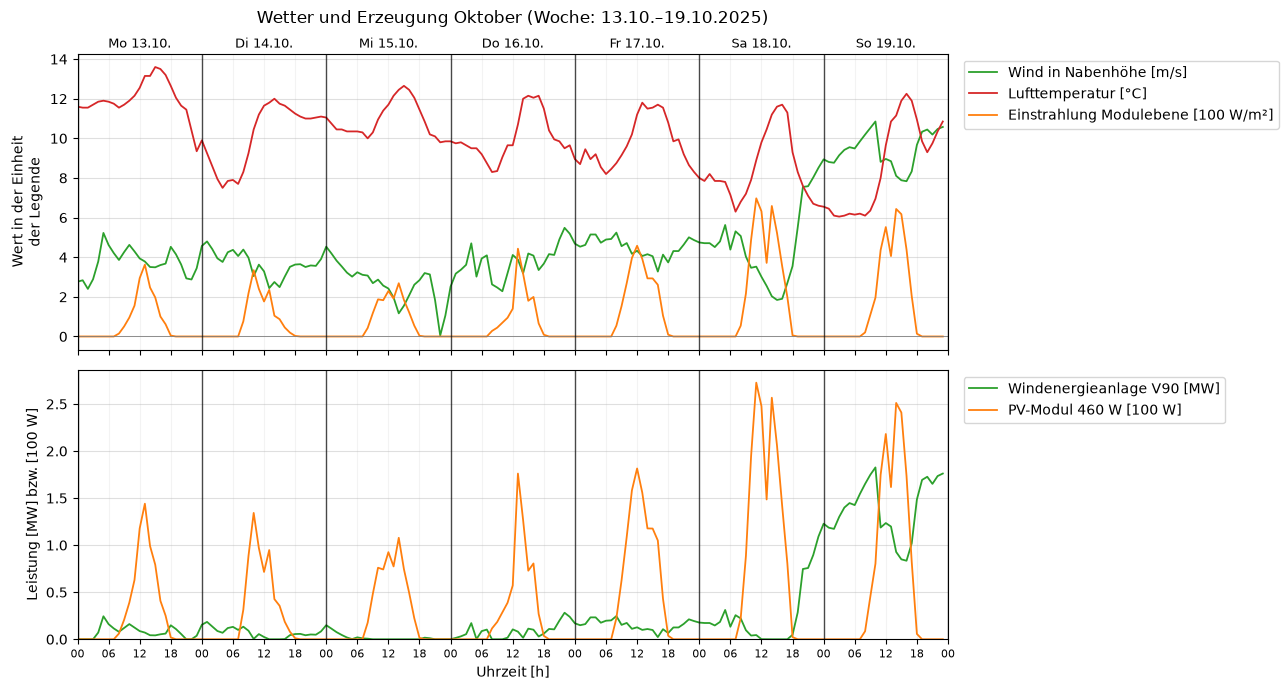

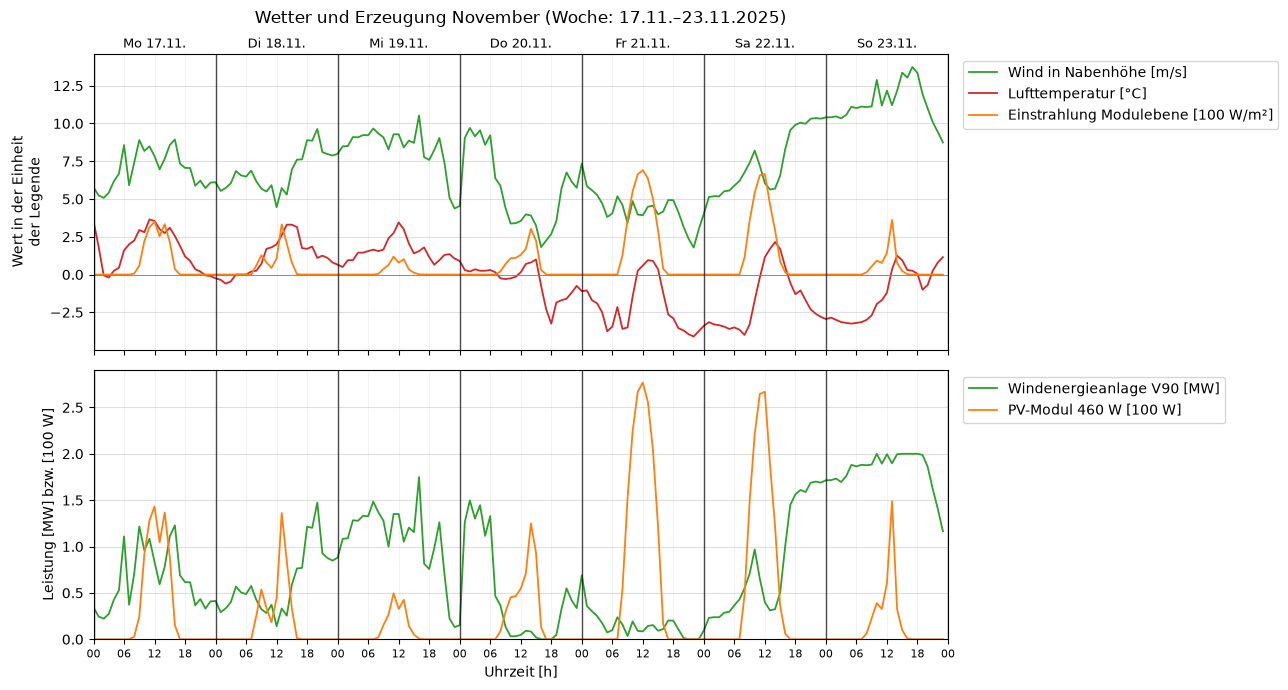

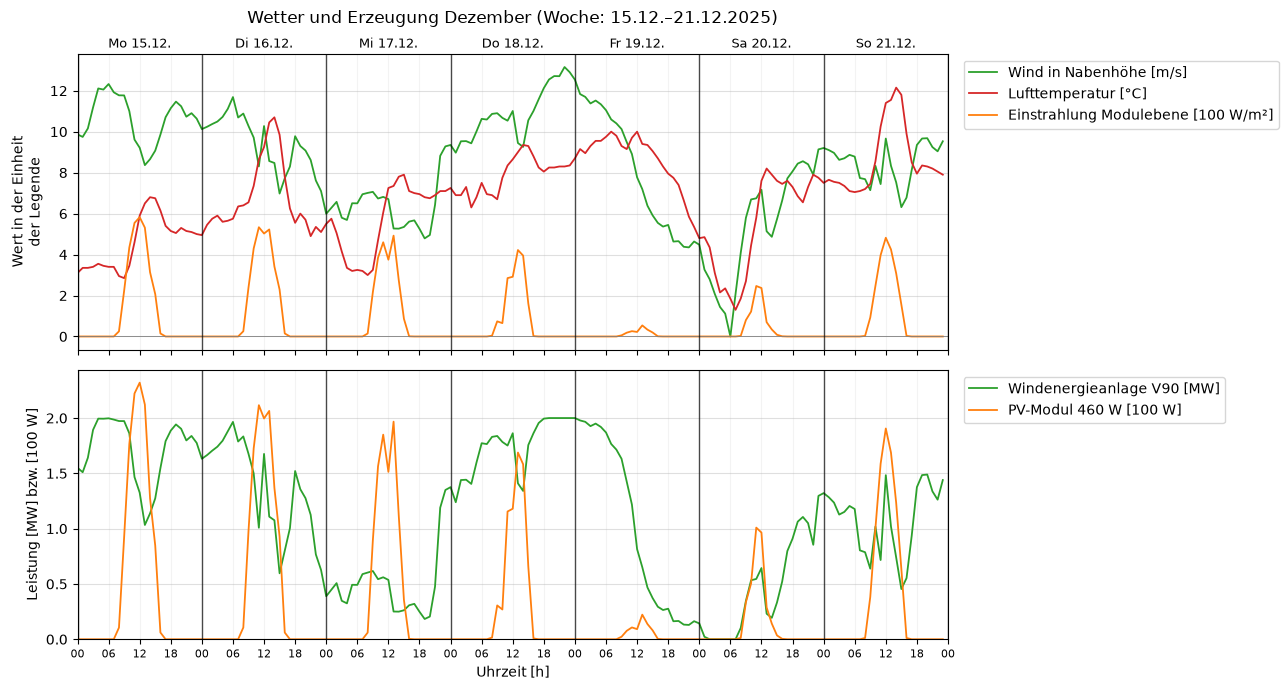

In [12]:
for month, w in WEATHER.items():
    plots.plot_weather_week(w, f"Wetter und Erzeugung {month.label} "
                               f"(Woche: {w.index[0]:%d.%m.}–{w.index[-1]:%d.%m.%Y})")
    plt.show()

### 1.5 Erzeugungsanlagen für die Szenarien in Task 4

| Anlage | Größe | Grundlage | Begründung |
|---|---|---|---|
| Windpark | 15 × Vestas V90-2.0 MW = 30 MW | Kennlinie und Wind auf Nabenhöhe aus 1.2 und 1.4 | Der Arbeitsauftrag gibt 15 WEA vor. Alle Anlagen erhalten dieselbe Windgeschwindigkeit (gleichzeitige Einspeisung). |
| PV-Freiflächenanlage | 10 MWp | PV-Leistung je kWp aus 1.3 und 1.4 | PV-Freiflächenanlagen sind Anlagen ab 1 MWp; die 18 Zuschläge der Innovationsausschreibung im April 2021 hatten zusammen 258 MW PV-Leistung, also im Mittel rund 14 MWp [22]. |

**Plausibilitätsprüfung der Erträge:** Aus den 12 typischen Wochen wird der Jahresertrag hochgerechnet (mittlere Wochenenergie × 52,14) und mit Literaturwerten verglichen. Für PV nennt [22] einen spezifischen Jahresertrag von 935 (Norden), 1105 (Mitte) und 1280 kWh/kWp (Süden) bei optimaler Neigung und Südausrichtung.

In [13]:
wochen = len(WEATHER)
pv_ertrag = sum(df["pv_kw_per_kwp"].sum() for df in WEATHER.values()) / wochen * 52.14        # kWh/kWp/a
wind_vlh = sum(df["wind_pu"].sum() for df in WEATHER.values()) / wochen * 52.14                # Volllaststunden
ertrag = pd.DataFrame({
    "Kennwert": ["spezifischer Ertrag [kWh/kWp/a]", "Volllaststunden [h/a]"],
    "Simulation": [pv_ertrag, wind_vlh],
    "Jahresenergie Anlage [GWh/a]": [pv_ertrag * 10_000 / 1e6, wind_vlh * 30 / 1000],
}, index=["PV-Freiflächenanlage 10 MWp", "Windpark 30 MW"])
ertrag.round(1)

,Kennwert,Simulation,Jahresenergie Anlage [GWh/a]
PV-Freiflächenanlage 10 MWp,spezifischer Ertrag [kWh/kWp/a],1222.6,12.2
Windpark 30 MW,Volllaststunden [h/a],2515.9,75.5


**Einordnung:** Der hochgerechnete PV-Ertrag liegt mit rund 1220 kWh/kWp zwischen den Werten für Mittel- und Süddeutschland in [22] und damit etwas über dem Wert für die Mitte. Gründe: optimale Ausrichtung im Modell, keine Verschmutzungs- und Verfügbarkeitsverluste und die Hochrechnung aus nur 12 typischen Wochen. Der Windpark erreicht rund 2500 Volllaststunden; das ist für einen Binnenlandstandort eher hoch, weil die Wetterwochen nach mittlerer Erzeugung ausgewählt wurden und weder Abschattung im Park noch Verfügbarkeitsverluste berücksichtigt sind. Beide Werte sind für die Netzuntersuchung ausreichend genau; entscheidend sind die Leistungsspitzen und ihre Gleichzeitigkeit mit der Last.

### Quellen zu den Daten

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025, S. 3–4. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[2] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Repräsentative Profile BDEW H25, G25, L25, P25, S25 – Veröffentlichung“, Datensatz (CSV, Profil Haushalte), Berlin, 2025.

[3] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Anwendung der Repräsentativen VDEW-Lastprofile step-by-step“, Berlin, 2000, S. 18 f. Online: https://www.bdew.de/media/documents/2000131_Anwendung-repraesentativen_Lastprofile-Step-by-step.pdf

[4] P. Zippenfenig, „Open-Meteo.com Weather API“, Zenodo, 2023, doi: 10.5281/ZENODO.7970649.

[5] H. Hersbach et al., „The ERA5 global reanalysis“, Quarterly Journal of the Royal Meteorological Society, Bd. 146, Nr. 730, S. 1999–2049, 2020, doi: 10.1002/qj.3803.

[6] Open-Meteo, „Historical Weather API – Documentation“. Online: https://open-meteo.com/en/docs/historical-weather-api (Abruf: 14.10.2026).

[7] wind-turbine-models.com, „Vestas V90“. Online: https://www.wind-turbine-models.com/turbines/16-vestas-v90 (Abruf: 14.10.2026).

[8] windpowerlib, Version 0.2.2, Turbinendatenbank der Open Energy Database (Datei `oedb/power_curves.csv`, Eintrag „V90/2000“). Online: https://github.com/wind-python/windpowerlib

[9] E. Hau, *Windkraftanlagen: Grundlagen, Technik, Einsatz, Wirtschaftlichkeit*, 6. Aufl. Berlin, Heidelberg: Springer Vieweg, 2016.

[10] Trina Solar, „Vertex S+ NEG9RC.27“, Produktseite. Online: https://www.trinasolar.com/de/NEG9RC.27/ (Abruf: 14.10.2026).

[11] Trina Solar, „Vertex S+ – Bifaziales Doppelglas N-Typ i-TOPCon Modul, TSM-NEG9RC.27“, Datenblatt, Version TSM_DE_2024_B, 2024. Online: https://www-cdn.trinasolar.com/wwwstorage/sites/8/250227_Datasheet_VertexS_NEG9RC.27_DE_2024_B_web.pdf

[12] J. A. Duffie und W. A. Beckman, *Solar Engineering of Thermal Processes*, 4. Aufl. Hoboken, NJ: Wiley, 2013.

[22] C. Kost et al., „Stromgestehungskosten Erneuerbare Energien“, Fraunhofer ISE, Freiburg, Juni 2021, Tabelle 3, S. 14. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/DE2021_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf

*Bei [3], [9] und [12] die verwendeten Seiten bzw. Kapitel anhand der eigenen Ausgabe ergänzen bzw. prüfen.*

## 2 Netzaufbau: CIGRE-Mittelspannungsnetz

Das CIGRE-MV-Netz ist ein Benchmarknetz der CIGRE Task Force C6.04.02 zur Untersuchung der Integration erneuerbarer und dezentraler Erzeugung [13]. Es bildet ein europäisches Mittelspannungsnetz (20 kV) ab, das aus einem 110-kV-Netz über zwei Umspanntransformatoren versorgt wird. In pandapower ist es als `pn.create_cigre_network_mv()` hinterlegt [14].

pandapower stellt das Netz in drei Varianten bereit:

| `with_der` | dezentrale Erzeugung |
|---|---|
| `False` | keine |
| `"pv_wind"` | 8 PV-Anlagen und 1 Windenergieanlage |
| `"all"` | zusätzlich Batteriespeicher, Brennstoffzellen, Mikro-KWK u. a. |

Verwendet wird die Variante **`"pv_wind"`**. Sie enthält genau die beiden Erzeugungsarten, für die in Abschnitt 1 Zeitreihen aufbereitet wurden. Die PV-Anlagen und die Windenergieanlage können damit später mit den saisonalen Wetterprofilen betrieben werden.

In [14]:
net = pn.create_cigre_network_mv(with_der="pv_wind")
net

This pandapower network includes the following parameter tables:
   - bus (15 elements)
   - load (18 elements)
   - sgen (9 elements)
   - switch (8 elements)
   - ext_grid (1 element)
   - line (15 elements)
   - trafo (2 elements)

### 2.1 Netzplan

![CIGRE-MV-Netz mit PV und Wind](cigre_network_mv_der.png)

*Bild: Netzplan des CIGRE-MV-Netzes mit PV- und Windanlagen (`with_der="pv_wind"`) aus der pandapower-Dokumentation [14], nach dem Benchmark-Netz der CIGRE Task Force C6.04.02 [13]. Quelle der Bilddatei: pandapower-Repository, `doc/pics/networks/cigre/cigre_network_mv_der.pnp` (BSD-3-Clause-Lizenz).*

Hinweis: Im Original-Benchmark [13] ist das vorgelagerte Netz mit 220 kV angegeben und es sind zusätzlich Batteriespeicher, Brennstoffzellen und BHKW enthalten. pandapower nimmt mangels Daten für einen 220/20-kV-Transformator 110 kV an und berücksichtigt in der Variante `pv_wind` nur die PV-Anlagen und die Windenergieanlage. Der Netzplan oben entspricht deshalb genau dem hier verwendeten Modell.

**Aufbau:**

- **Einspeisung:** Das externe Netz (110 kV, Slack mit 1,03 pu) speist an Bus 0. Zwei Transformatoren 110/20 kV mit je 25 MVA versorgen die beiden Abgänge.
- **Abgang 1 (Bus 1 bis Bus 11):** Kabelnetz in Ringstruktur mit Abzweig. Die Ringe sind über die offenen Trennschalter **S2** (Leitung 6-7) und **S3** (Leitung 11-4) aufgetrennt, sodass das Netz im Normalbetrieb **strahlenförmig** betrieben wird.
- **Abgang 2 (Bus 12 bis Bus 14):** Freileitungen.
- **Kupplung der Abgänge:** Der offene Trennschalter **S1** (Leitung 14-8) verbindet Abgang 2 mit Abgang 1. Durch Schließen von S1, S2 oder S3 kann bei Störungen umgeschaltet werden (Wiederversorgung).
- **Dezentrale Erzeugung:** acht PV-Anlagen mit 10–40 kW (zusammen 0,21 MW) an den Bussen 3, 4, 5, 6, 8, 9, 10 und 11 sowie eine Windenergieanlage mit 1,5 MW an Bus 7.
- **Lasten:** An den meisten Bussen hängen Wohngebiete (R, *residential*) und/oder Gewerbe/Industrie (CI, *commercial/industrial*). Die großen Lasten an Bus 1 und Bus 12 liegen direkt an den Unterspannungssammelschienen der Transformatoren und bilden die Belastung durch weitere, nicht einzeln modellierte Abgänge nach.

### 2.2 Komponenten

In [15]:
plots.component_overview(net)

,Element,Anzahl
Tabelle,,
net.bus,Sammelschienen / Knoten,15
net.line,Leitungen,15
net.trafo,Zweiwicklungstransformatoren,2
net.switch,Schalter,8
net.ext_grid,externes Netz (Slack),1
net.load,Lasten,18
net.sgen,statische Erzeuger,9


#### Sammelschienen (`net.bus`)

In [16]:
net.bus[["name", "vn_kv", "type", "zone", "in_service"]]

,name,vn_kv,type,zone,in_service
0,Bus 0,110.0,b,CIGRE_MV,True
1,Bus 1,20.0,b,CIGRE_MV,True
2,Bus 2,20.0,b,CIGRE_MV,True
3,Bus 3,20.0,b,CIGRE_MV,True
4,Bus 4,20.0,b,CIGRE_MV,True
5,Bus 5,20.0,b,CIGRE_MV,True
6,Bus 6,20.0,b,CIGRE_MV,True
7,Bus 7,20.0,b,CIGRE_MV,True
8,Bus 8,20.0,b,CIGRE_MV,True
9,Bus 9,20.0,b,CIGRE_MV,True


#### Transformatoren (`net.trafo`)

In [17]:
net.trafo[["name", "hv_bus", "lv_bus", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "vkr_percent",
           "pfe_kw", "i0_percent", "shift_degree", "tap_side", "tap_pos"]]

,name,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,i0_percent,shift_degree,tap_side,tap_pos
0,Trafo 0-1,0,1,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,None,NaN
1,Trafo 0-12,0,12,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,None,NaN


Die Transformatoren haben im pandapower-Modell **keinen Stufenschalter** (`tap_side` und `tap_pos` leer). Die Spannung im 20-kV-Netz wird allein durch die Slack-Spannung von 1,03 pu und die Spannungsfälle bestimmt.

#### Leitungen (`net.line`)

In [18]:
net.line[["name", "from_bus", "to_bus", "length_km", "std_type", "type",
          "r_ohm_per_km", "x_ohm_per_km", "c_nf_per_km", "max_i_ka"]]

,name,from_bus,to_bus,length_km,std_type,type,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka
0,Line 1-2,1,2,2.82,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
1,Line 2-3,2,3,4.42,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
2,Line 3-4,3,4,0.61,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
3,Line 4-5,4,5,0.56,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
4,Line 5-6,5,6,1.54,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
5,Line 7-8,7,8,1.67,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
6,Line 8-9,8,9,0.32,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
7,Line 9-10,9,10,0.77,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
8,Line 10-11,10,11,0.33,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
9,Line 3-8,3,8,1.30,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145


In [19]:
(net.line.groupby("std_type")
    .agg(Anzahl=("length_km", "size"), Gesamtlänge_km=("length_km", "sum"),
         Typ=("type", "first"), r_ohm_per_km=("r_ohm_per_km", "first"),
         x_ohm_per_km=("x_ohm_per_km", "first"), c_nf_per_km=("c_nf_per_km", "first"),
         max_i_ka=("max_i_ka", "first")))

,Anzahl,Gesamtlänge_km,Typ,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka
std_type,,,,,,,
CABLE_CIGRE_MV,12,15.07,cs,0.501,0.716,151.17490,0.145
OHL_CIGRE_MV,3,9.88,ol,0.510,0.366,10.09679,0.195


Es gibt zwei Leitungstypen: Kabel (`cs`, Abgang 1 und Kupplungen) und Freileitungen (`ol`, Abgang 2). Bei den Kabeln ist die Reaktanz größer als der Widerstand (X/R ≈ 1,4), anders als im Niederspannungsnetz aus Task 1 und 2. Die Kapazität der Kabel ist etwa 15-mal so groß wie die der Freileitungen.

#### Schalter (`net.switch`)

In [20]:
sw = net.switch.copy()
sw["Leitung/Trafo"] = [net.line.at[e, "name"] if et == "l" else net.trafo.at[e, "name"]
                       for e, et in zip(sw.element, sw.et)]
sw["an Bus"] = net.bus.loc[sw.bus, "name"].to_numpy()
sw[["name", "type", "closed", "et", "Leitung/Trafo", "an Bus"]]

,name,type,closed,et,Leitung/Trafo,an Bus
0,None,LBS,True,l,Line 6-7,Bus 6
1,S2,LBS,False,l,Line 6-7,Bus 7
2,S3,LBS,False,l,Line 11-4,Bus 4
3,None,LBS,True,l,Line 11-4,Bus 11
4,S1,LBS,False,l,Line 14-8,Bus 8
5,None,LBS,True,l,Line 14-8,Bus 14
6,None,CB,True,t,Trafo 0-1,Bus 0
7,None,CB,True,t,Trafo 0-12,Bus 0


| Typ | Bedeutung |
|---|---|
| `LBS` | Lasttrennschalter (*load break switch*) an den Leitungsenden; offen: S1, S2, S3 als Trennstellen |
| `CB` | Leistungsschalter (*circuit breaker*) an der Oberspannungsseite der Transformatoren |
| `et = "l"` / `"t"` | Schalter an einer Leitung bzw. einem Transformator |

#### Externes Netz (`net.ext_grid`)

In [21]:
net.ext_grid[["bus", "vm_pu", "va_degree", "s_sc_max_mva", "rx_max"]]

,bus,vm_pu,va_degree,s_sc_max_mva,rx_max
0,0,1.03,0.0,5000.0,0.1


#### Lasten (`net.load`)

In [22]:
loads = net.load[["name", "bus", "p_mw", "q_mvar", "sn_mva"]].copy()
loads["Art"] = np.where(loads.name.str.contains("CI"), "Gewerbe/Industrie", "Wohngebiet")
loads["cos φ"] = loads.p_mw / np.hypot(loads.p_mw, loads.q_mvar)
loads.round(3)

,name,bus,p_mw,q_mvar,sn_mva,Art,cos φ
0,Load R1,1,14.994,3.045,15.300,Wohngebiet,0.98
1,Load R3,3,0.276,0.069,0.285,Wohngebiet,0.97
2,Load R4,4,0.432,0.108,0.445,Wohngebiet,0.97
3,Load R5,5,0.728,0.182,0.750,Wohngebiet,0.97
4,Load R6,6,0.548,0.137,0.565,Wohngebiet,0.97
5,Load R8,8,0.587,0.147,0.605,Wohngebiet,0.97
6,Load R10,10,0.475,0.119,0.490,Wohngebiet,0.97
7,Load R11,11,0.330,0.083,0.340,Wohngebiet,0.97
8,Load R12,12,14.994,3.045,15.300,Wohngebiet,0.98
9,Load R14,14,0.209,0.052,0.215,Wohngebiet,0.97


In [23]:
summary = loads.groupby("Art").agg(Anzahl=("p_mw", "size"), P_MW=("p_mw", "sum"), Q_Mvar=("q_mvar", "sum"))
summary.loc["Summe"] = summary.sum()
summary.round(2)

,Anzahl,P_MW,Q_Mvar
Art,,,
Gewerbe/Industrie,8.0,11.17,4.05
Wohngebiet,10.0,33.57,6.99
Summe,18.0,44.74,11.04


#### Dezentrale Erzeugung (`net.sgen`)

In [24]:
gens = net.sgen[["name", "bus", "type", "p_mw", "q_mvar", "sn_mva", "in_service"]].copy()
gens["Art"] = gens["type"].map({"PV": "Photovoltaik", "WP": "Windenergie"})
gens

,name,bus,type,p_mw,q_mvar,sn_mva,in_service,Art
0,PV 3,3,PV,0.02,0.0,0.02,True,Photovoltaik
1,PV 4,4,PV,0.02,0.0,0.02,True,Photovoltaik
2,PV 5,5,PV,0.03,0.0,0.03,True,Photovoltaik
3,PV 6,6,PV,0.03,0.0,0.03,True,Photovoltaik
4,PV 8,8,PV,0.03,0.0,0.03,True,Photovoltaik
5,PV 9,9,PV,0.03,0.0,0.03,True,Photovoltaik
6,PV 10,10,PV,0.04,0.0,0.04,True,Photovoltaik
7,PV 11,11,PV,0.01,0.0,0.01,True,Photovoltaik
8,WKA 7,7,WP,1.50,0.0,1.50,True,Windenergie


In [25]:
gen_sum = gens.groupby("Art").agg(Anzahl=("p_mw", "size"), P_MW=("p_mw", "sum"))
gen_sum["Anteil an der Gesamtlast [%]"] = gen_sum.P_MW / net.load.p_mw.sum() * 100
gen_sum.round(3)

,Anzahl,P_MW,Anteil an der Gesamtlast [%]
Art,,,
Photovoltaik,8,0.21,0.469
Windenergie,1,1.50,3.353


Die Erzeugungsanlagen speisen mit cos φ = 1 (keine Blindleistung). Die angegebene Leistung `p_mw` ist ein fester Arbeitspunkt; für die saisonale Untersuchung wird sie später über die PV- und Windzeitreihen aus Abschnitt 1 vorgegeben. Mit zusammen 1,71 MW ist die installierte Erzeugung klein im Vergleich zur Gesamtlast von 44,7 MW, wirkt aber lokal: Die Windenergieanlage an Bus 7 speist in Abgang 1 ein, der im Netz ohne Erzeugung die niedrigsten Spannungen aufweist.

### Quellen zum Netz

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

*Kapitel und Seiten von [13] anhand der verwendeten Ausgabe ergänzen.*